# CHƯƠNG 4. CHUẨN BỊ DỮ LIỆU CHO MÔ HÌNH HÓA

Notebook này thực hiện kế hoạch tuần 4 trên các tập dữ liệu đã tiền xử lý ở Chương 3
(`data/preprocessed/`). Notebook **chỉ đọc** dữ liệu của Chương 3; không sửa `preprocess.ipynb`,
`modeling.ipynb` hay các CSV đã xuất.

## 4.1. Rà soát và xây dựng phương án chia dữ liệu

Phương án chia được chốt như sau:

| Thành phần | Lựa chọn |
| --- | --- |
| Biến mục tiêu | `final_result`, giữ nguyên **4 nhãn** gốc (Pass, Distinction, Fail, Withdrawn) |
| Đơn vị nhóm | `id_student` — mọi lượt học của một sinh viên nằm trọn trong một tập/một fold |
| Tập kiểm tra | Hold-out ~20% sinh viên, **không dùng** trong tuần 4 (chỉ đánh giá cuối cùng) |
| Tập huấn luyện | ~80% còn lại, chia **5 fold** để cross-validation khi chọn mô hình và tham số |
| Phương pháp | `StratifiedGroupKFold` (phân tầng theo `final_result`, nhóm theo `id_student`) |
| Nơi gán | Gán **một lần** trên `student_base` rồi dùng chung cho cả 5 mốc dự đoán |
| Tái lập | `random_state = 42` |

Đầu ra: `data/preprocessed/split_assignment.csv` (mỗi sinh viên một dòng: `split`, `fold`),
`data/preprocessed/split_manifest.json`, các bảng `report/tables/4_1_*.csv` và hình `report/figures/4_1_*.png`.

## Thiết lập thư viện, đường dẫn và hàm hỗ trợ

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
import sklearn

# Cho phép chạy từ thư mục dự án hoặc thư mục cha.
ROOT = next((p for p in (Path.cwd(), Path.cwd() / 'oulad_project')
             if (p / 'data' / 'preprocessed' / 'student_base.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ oulad_project/ hoặc thư mục cha; cần chạy preprocess.ipynb trước.')
PRE_DIR = ROOT / 'data' / 'preprocessed'
FIG_DIR = ROOT / 'report' / 'figures'
TABLE_DIR = ROOT / 'report' / 'tables'
for directory in (FIG_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Hằng số và hàm dùng chung nằm trong src/modeling_pipeline.py (một bản code duy nhất cho notebook và bước sau).
sys.path.insert(0, str(ROOT / 'src'))
import modeling_pipeline as mp
from modeling_pipeline import STUDENT_KEY, TARGET, LABELS, WEEKS, SEED, N_FOLDS
# LABELS cùng thứ tự Hình 2 của Chương 2; SEED = 42; N_FOLDS = 5 fold cross-validation trên tập huấn luyện.
TEST_SPLITS = 5     # lấy 1/5 nhóm sinh viên làm tập kiểm tra (~20%)

BASE_PATH = PRE_DIR / 'student_base.csv'
WEEK_PATHS = {w: PRE_DIR / f'oulad_week{w}.csv' for w in WEEKS}
ASSIGN_PATH = PRE_DIR / 'split_assignment.csv'
MANIFEST_PATH = PRE_DIR / 'split_manifest.json'

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

# Tệp của nhóm chỉ được đọc: ghi lại SHA-256 để đối chiếu ở cuối notebook.
protected_paths = [BASE_PATH, *WEEK_PATHS.values(), PRE_DIR / 'feature_manifest.json',
                   ROOT / 'preprocess.ipynb', ROOT / 'modeling.ipynb']
protected_before = {p.relative_to(ROOT).as_posix(): sha256_file(p) for p in protected_paths}

def vn_int(x):
    return f'{int(x):,}'.replace(',', '.')

def vn_pct(x, digits=2):
    return f'{x:.{digits}f}'.replace('.', ',') + '%'

def comment(text):
    display(Markdown('**Nhận xét:** ' + text))

def save_table(df, name):
    path = TABLE_DIR / f'{name}.csv'
    df.to_csv(path, index=False, encoding='utf-8-sig')
    return path

def save_figure(fig, name):
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight', facecolor='white')
    return path

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10,
                     'font.family': 'DejaVu Sans'})
COLOR = {'Train': '#55606a', 'Test': '#8fb3a0'}
FOLD_COLORS = ['#55606a', '#4c78a8', '#8fb3a0', '#b07d62', '#c9b26b']
LABEL_COLORS = {'Pass': '#55606a', 'Withdrawn': '#b07d62', 'Fail': '#4c78a8', 'Distinction': '#8fb3a0'}
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.6.1 | pandas 2.3.3


### 4.1.1. Dữ liệu đầu vào

`student_base` chứa toàn bộ 32.593 lượt học (chưa lọc theo mốc); mỗi tệp `oulad_weekN.csv` là tập con của
bảng này. Vì vậy việc gán sinh viên vào tập/fold được thực hiện trên `student_base` để bao phủ mọi sinh viên
xuất hiện ở bất kỳ mốc nào. Chỉ các cột khóa, nhãn và mã học phần–đợt học được đọc; các đặc trưng chưa dùng ở bước này.

In [2]:
base = pd.read_csv(BASE_PATH, usecols=STUDENT_KEY + [TARGET],
                   dtype={'code_module': 'string', 'code_presentation': 'string',
                          'id_student': 'int64', TARGET: 'string'})
weeks = {w: pd.read_csv(path, usecols=STUDENT_KEY + ['prediction_week', 'cutoff_day', TARGET],
                        dtype={'code_module': 'string', 'code_presentation': 'string',
                               'id_student': 'int64', TARGET: 'string'})
         for w, path in WEEK_PATHS.items()}

# Kiểm tra đầu vào: khóa duy nhất, nhãn hợp lệ, mỗi tệp mốc là tập con của student_base và nhãn khớp.
assert not base.duplicated(STUDENT_KEY).any(), 'Khóa lượt học trong student_base bị trùng'
assert set(base[TARGET]) == set(LABELS) and base[TARGET].notna().all()
for w, df in weeks.items():
    assert not df.duplicated(STUDENT_KEY).any(), f'Tuần {w}: khóa trùng'
    assert (df['prediction_week'] == w).all()
    check = df.merge(base, on=STUDENT_KEY, how='left', suffixes=('', '_base'), validate='one_to_one')
    assert check[TARGET + '_base'].notna().all(), f'Tuần {w}: có lượt học không có trong student_base'
    assert (check[TARGET] == check[TARGET + '_base']).all(), f'Tuần {w}: nhãn không khớp student_base'

def describe_input(name, df):
    per_student = df.groupby('id_student').size()
    return {'Tập dữ liệu': name, 'Số lượt học': len(df), 'Số sinh viên': df['id_student'].nunique(),
            'Số sinh viên có nhiều lượt học': int((per_student > 1).sum()),
            'Số lượt học của sinh viên có nhiều lượt học': int(per_student[per_student > 1].sum())}

input_overview = pd.DataFrame([describe_input('student_base', base)] +
                              [describe_input(f'oulad_week{w}', weeks[w]) for w in WEEKS])
save_table(input_overview, '4_1_1_input_overview')
display(input_overview)
b = input_overview.iloc[0]
comment(f"`student_base` có {vn_int(b['Số lượt học'])} lượt học của {vn_int(b['Số sinh viên'])} sinh viên; "
        f"{vn_int(b['Số sinh viên có nhiều lượt học'])} sinh viên có từ hai lượt học trở lên "
        f"({vn_int(b['Số lượt học của sinh viên có nhiều lượt học'])} lượt). Nếu chia ngẫu nhiên theo dòng, "
        "các lượt học của cùng một sinh viên có thể rơi vào cả tập huấn luyện và tập kiểm tra, khiến kết quả "
        "đánh giá lạc quan hơn thực tế. Cả 5 tệp mốc đều là tập con của `student_base` với nhãn khớp hoàn toàn.")

,Tập dữ liệu,Số lượt học,Số sinh viên,Số sinh viên có nhiều lượt học,Số lượt học của sinh viên có nhiều lượt học
0,student_base,32593,28785,3538,7346
1,oulad_week4,27528,24835,2574,5267
2,oulad_week8,26516,24112,2312,4716
3,oulad_week12,25722,23505,2145,4362
4,oulad_week16,24932,22965,1912,3879
5,oulad_week24,23562,21937,1595,3220


**Nhận xét:** `student_base` có 32.593 lượt học của 28.785 sinh viên; 3.538 sinh viên có từ hai lượt học trở lên (7.346 lượt). Nếu chia ngẫu nhiên theo dòng, các lượt học của cùng một sinh viên có thể rơi vào cả tập huấn luyện và tập kiểm tra, khiến kết quả đánh giá lạc quan hơn thực tế. Cả 5 tệp mốc đều là tập con của `student_base` với nhãn khớp hoàn toàn.

### 4.1.2. Tách tập kiểm tra (hold-out ~20%)

`StratifiedGroupKFold` với 5 phần được áp dụng trên `student_base` (nhãn `final_result`, nhóm `id_student`);
phần thứ nhất được giữ làm tập kiểm tra. Cách này cho tập kiểm tra ~20% số lượt học, giữ trọn nhóm sinh viên
và cân bằng gần đúng tỷ lệ 4 nhãn. Do một sinh viên có thể có nhiều lượt học với nhãn khác nhau, việc phân tầng
chỉ đạt gần đúng.

In [3]:
outer = StratifiedGroupKFold(n_splits=TEST_SPLITS, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(base, base[TARGET], groups=base['id_student']))
test_students = set(base['id_student'].iloc[test_idx])
train_base = base.iloc[train_idx].reset_index(drop=True)
assert test_students.isdisjoint(set(train_base['id_student']))
print(f'Tập huấn luyện: {len(train_idx):,} lượt học | Tập kiểm tra: {len(test_idx):,} lượt học '
      f'({len(test_idx) / len(base):.2%}) | Sinh viên kiểm tra: {len(test_students):,}')

Tập huấn luyện: 26,105 lượt học | Tập kiểm tra: 6,488 lượt học (19.91%) | Sinh viên kiểm tra: 5,762


### 4.1.3. Chia 5 fold trên tập huấn luyện

Phần huấn luyện tiếp tục được chia thành 5 fold bằng `StratifiedGroupKFold` (cùng `random_state`).
Mỗi sinh viên thuộc đúng một fold; fold `k` là tập validation của vòng `k`, 4 fold còn lại dùng để huấn luyện.

In [4]:
inner = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_of_student = {}
for fold, (_, val_idx) in enumerate(inner.split(train_base, train_base[TARGET],
                                                groups=train_base['id_student']), start=1):
    for sid in train_base['id_student'].iloc[val_idx].unique():
        assert sid not in fold_of_student
        fold_of_student[int(sid)] = fold

students = pd.DataFrame({'id_student': np.sort(base['id_student'].unique())})
students['split'] = np.where(students['id_student'].isin(test_students), 'test', 'train')
students['fold'] = students['id_student'].map(fold_of_student).astype('Int64')

assert students['id_student'].is_unique
assert students.loc[students['split'] == 'train', 'fold'].notna().all()
assert students.loc[students['split'] == 'test', 'fold'].isna().all()
display(students.groupby('split', dropna=False)['id_student'].count().rename('Số sinh viên').to_frame())
display(students['fold'].value_counts(dropna=False).sort_index().rename('Số sinh viên').to_frame())

,Số sinh viên
split,
test,5762
train,23023


,Số sinh viên
fold,
1,4608
2,4608
3,4602
4,4598
5,4607
<NA>,5762


### 4.1.4. Lưu phương án chia

Phương án được lưu ở cấp **sinh viên** (`id_student` → `split`, `fold`) để mọi thành viên nhóm và mọi mốc dự đoán
dùng chung. Tệp manifest ghi lại cấu hình và mã băm để kiểm tra tính tái lập.

In [5]:
students.to_csv(ASSIGN_PATH, index=False, encoding='utf-8')
reloaded = pd.read_csv(ASSIGN_PATH, dtype={'id_student': 'int64', 'split': 'string', 'fold': 'Int64'})
assert reloaded.equals(students.astype({'split': 'string'})), 'Đọc lại split_assignment.csv không khớp'

manifest = {
    'schema_version': 1,
    'created_at': datetime.now().astimezone().isoformat(timespec='seconds'),
    'source': 'data/preprocessed/student_base.csv',
    'source_sha256': protected_before['data/preprocessed/student_base.csv'],
    'unit_of_assignment': 'id_student',
    'target_column': TARGET,
    'target_labels': LABELS,
    'method': 'StratifiedGroupKFold(stratify=final_result, groups=id_student)',
    'test_selection': f'first of {TEST_SPLITS} outer splits (~{100 / TEST_SPLITS:.0f}% of enrolments)',
    'n_folds': N_FOLDS,
    'random_state': SEED,
    'scikit_learn_version': sklearn.__version__,
    'columns': {'id_student': 'student id', 'split': 'train | test',
                'fold': '1..5 for train students; empty for test students'},
    'usage': ('Merge on id_student into oulad_weekN.csv. Never use split == test before the final evaluation. '
              'Fit every learned transformation inside the training folds only.'),
    'n_students': {'total': int(len(students)), 'train': int((students['split'] == 'train').sum()),
                   'test': int((students['split'] == 'test').sum())},
    'assignment_file': 'data/preprocessed/split_assignment.csv',
    'assignment_sha256': sha256_file(ASSIGN_PATH),
}
MANIFEST_PATH.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print(ASSIGN_PATH.relative_to(ROOT), '|', MANIFEST_PATH.relative_to(ROOT))

data\preprocessed\split_assignment.csv | data\preprocessed\split_manifest.json


### 4.1.5. Kiểm tra phương án chia trên năm mốc dự đoán

Phương án gán ở cấp sinh viên được ghép vào từng tệp `oulad_weekN.csv`. Với mỗi mốc, các phép kiểm tra gồm:
quy mô từng tập, giao thoa sinh viên giữa các tập (phải bằng 0), phân phối 4 nhãn và phân phối học phần–đợt học.

In [6]:
def attach_split(df):
    out = df.merge(students, on='id_student', how='left', validate='many_to_one')
    assert out['split'].notna().all(), 'Có lượt học chưa được gán tập'
    return out

datasets = {'student_base': attach_split(base), **{f'Tuần {w}': attach_split(weeks[w]) for w in WEEKS}}

# (a) Quy mô từng tập.
size_rows, fold_rows = [], []
for name, df in datasets.items():
    tr, te = df[df['split'] == 'train'], df[df['split'] == 'test']
    size_rows.append({'Tập dữ liệu': name, 'Tổng số lượt học': len(df),
                      'Số lượt học huấn luyện': len(tr), 'Số lượt học kiểm tra': len(te),
                      'Tỷ lệ kiểm tra (%)': round(100 * len(te) / len(df), 2),
                      'Số sinh viên huấn luyện': tr['id_student'].nunique(),
                      'Số sinh viên kiểm tra': te['id_student'].nunique()})
    counts = tr['fold'].value_counts().sort_index()
    fold_rows.append({'Tập dữ liệu': name, **{f'Fold {k}': int(counts.get(k, 0)) for k in range(1, N_FOLDS + 1)},
                      'Chênh lệch lớn nhất/nhỏ nhất (%)': round(100 * (counts.max() / counts.min() - 1), 2)})
split_size = pd.DataFrame(size_rows)
fold_size = pd.DataFrame(fold_rows)
save_table(split_size, '4_1_5_split_size')
save_table(fold_size, '4_1_5_fold_size')
display(split_size, fold_size)

# (b) Giao thoa sinh viên.
overlap_rows = []
for name, df in datasets.items():
    tr_ids = set(df.loc[df['split'] == 'train', 'id_student'])
    te_ids = set(df.loc[df['split'] == 'test', 'id_student'])
    fold_ids = {k: set(df.loc[df['fold'] == k, 'id_student']) for k in range(1, N_FOLDS + 1)}
    fold_overlap = max(len(fold_ids[i] & fold_ids[j])
                       for i in range(1, N_FOLDS + 1) for j in range(i + 1, N_FOLDS + 1))
    overlap_rows.append({'Tập dữ liệu': name,
                         'Sinh viên chung huấn luyện–kiểm tra': len(tr_ids & te_ids),
                         'Sinh viên chung lớn nhất giữa hai fold': fold_overlap})
overlap = pd.DataFrame(overlap_rows)
assert (overlap.iloc[:, 1:] == 0).all().all(), 'Có sinh viên xuất hiện ở hai tập/fold'
save_table(overlap, '4_1_5_student_overlap')
display(overlap)
comment(f"Ở cả 5 mốc, tập kiểm tra chiếm từ {vn_pct(split_size['Tỷ lệ kiểm tra (%)'].iloc[1:].min())} đến "
        f"{vn_pct(split_size['Tỷ lệ kiểm tra (%)'].iloc[1:].max())} số lượt học. Không có sinh viên nào đồng thời "
        "thuộc tập huấn luyện và tập kiểm tra, hay thuộc hai fold khác nhau. Vì gán ở cấp sinh viên và dùng chung, "
        "một sinh viên thuộc tập kiểm tra ở mốc này cũng không xuất hiện trong tập huấn luyện của mốc khác.")

,Tập dữ liệu,Tổng số lượt học,Số lượt học huấn luyện,Số lượt học kiểm tra,Tỷ lệ kiểm tra (%),Số sinh viên huấn luyện,Số sinh viên kiểm tra
0,student_base,32593,26105,6488,19.91,23023,5762
1,Tuần 4,27528,22042,5486,19.93,19879,4956
2,Tuần 8,26516,21210,5306,20.01,19290,4822
3,Tuần 12,25722,20572,5150,20.02,18800,4705
4,Tuần 16,24932,19950,4982,19.98,18381,4584
5,Tuần 24,23562,18856,4706,19.97,17546,4391


,Tập dữ liệu,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Chênh lệch lớn nhất/nhỏ nhất (%)
0,student_base,5232,5189,5243,5230,5211,1.04
1,Tuần 4,4469,4320,4395,4450,4408,3.45
2,Tuần 8,4291,4180,4213,4277,4249,2.66
3,Tuần 12,4178,4057,4092,4145,4100,2.98
4,Tuần 16,4059,3951,3960,3991,3989,2.73
5,Tuần 24,3843,3740,3739,3768,3766,2.78


,Tập dữ liệu,Sinh viên chung huấn luyện–kiểm tra,Sinh viên chung lớn nhất giữa hai fold
0,student_base,0,0
1,Tuần 4,0,0
2,Tuần 8,0,0
3,Tuần 12,0,0
4,Tuần 16,0,0
5,Tuần 24,0,0


**Nhận xét:** Ở cả 5 mốc, tập kiểm tra chiếm từ 19,93% đến 20,02% số lượt học. Không có sinh viên nào đồng thời thuộc tập huấn luyện và tập kiểm tra, hay thuộc hai fold khác nhau. Vì gán ở cấp sinh viên và dùng chung, một sinh viên thuộc tập kiểm tra ở mốc này cũng không xuất hiện trong tập huấn luyện của mốc khác.

In [7]:
# (c) Phân phối 4 nhãn theo tập và fold.
def label_pct(series):
    return (series.value_counts(normalize=True).reindex(LABELS, fill_value=0) * 100)

label_rows, deviation_rows = [], []
for name, df in datasets.items():
    parts = {'Toàn bộ': df, 'Huấn luyện': df[df['split'] == 'train'], 'Kiểm tra': df[df['split'] == 'test'],
             **{f'Fold {k}': df[df['fold'] == k] for k in range(1, N_FOLDS + 1)}}
    pct = {part: label_pct(sub[TARGET]) for part, sub in parts.items()}
    for part, sub in parts.items():
        label_rows.append({'Tập dữ liệu': name, 'Phần dữ liệu': part, 'Số lượt học': len(sub),
                           **{f'{lab} (%)': round(pct[part][lab], 2) for lab in LABELS}})
    fold_dev = max((pct[f'Fold {k}'] - pct['Huấn luyện']).abs().max() for k in range(1, N_FOLDS + 1))
    deviation_rows.append({'Tập dữ liệu': name,
                           'Lệch nhãn lớn nhất huấn luyện–kiểm tra (điểm %)':
                               round((pct['Huấn luyện'] - pct['Kiểm tra']).abs().max(), 2),
                           'Lệch nhãn lớn nhất fold–huấn luyện (điểm %)': round(fold_dev, 2)})
label_distribution = pd.DataFrame(label_rows)
save_table(label_distribution, '4_1_5_label_distribution')
display(label_distribution[label_distribution['Phần dữ liệu'].isin(['Toàn bộ', 'Huấn luyện', 'Kiểm tra'])])

# (d) Phân phối học phần–đợt học giữa huấn luyện và kiểm tra.
def course_pct(df):
    key = df['code_module'] + ' ' + df['code_presentation']
    return key.value_counts(normalize=True) * 100

course_dev = {}
for name, df in datasets.items():
    a, c = course_pct(df[df['split'] == 'train']), course_pct(df[df['split'] == 'test'])
    course_dev[name] = round(a.subtract(c, fill_value=0).abs().max(), 2)
deviation = pd.DataFrame(deviation_rows)
deviation['Lệch học phần–đợt học lớn nhất huấn luyện–kiểm tra (điểm %)'] = deviation['Tập dữ liệu'].map(course_dev)
save_table(deviation, '4_1_5_split_balance')
display(deviation)

module_rows = []
bdf = datasets['student_base']
for part, sub in (('Huấn luyện', bdf[bdf['split'] == 'train']), ('Kiểm tra', bdf[bdf['split'] == 'test'])):
    shares = (sub['code_module'] + ' ' + sub['code_presentation']).value_counts(normalize=True) * 100
    for key, val in shares.items():
        module_rows.append({'Phần dữ liệu': part, 'Mã học phần': key.split()[0],
                            'Mã đợt học': key.split()[1], 'Tỷ lệ lượt học (%)': round(val, 2)})
course_distribution = (pd.DataFrame(module_rows)
                       .pivot_table(index=['Mã học phần', 'Mã đợt học'], columns='Phần dữ liệu',
                                    values='Tỷ lệ lượt học (%)', fill_value=0).reset_index())
course_distribution.columns.name = None
course_distribution['Chênh lệch (điểm %)'] = (course_distribution['Huấn luyện']
                                              - course_distribution['Kiểm tra']).round(2)
save_table(course_distribution, '4_1_5_course_distribution')

wk = deviation.iloc[1:]
comment(f"Độ lệch tỷ lệ nhãn giữa huấn luyện và kiểm tra lớn nhất là "
        f"{vn_pct(wk.iloc[:, 1].max())} (điểm phần trăm) trên 5 mốc; giữa từng fold và toàn bộ phần huấn luyện "
        f"tối đa {vn_pct(wk.iloc[:, 2].max())}. Tỷ trọng từng học phần–đợt học giữa hai tập lệch tối đa "
        f"{vn_pct(wk.iloc[:, 3].max())} dù không được dùng làm tiêu chí phân tầng. Tỷ lệ nhãn thay đổi giữa các mốc "
        "(Withdrawn giảm dần) là do điều kiện tham gia tại ngày chốt, không phải do phương án chia.")

,Tập dữ liệu,Phần dữ liệu,Số lượt học,Pass (%),Withdrawn (%),Fail (%),Distinction (%)
0,student_base,Toàn bộ,32593,37.93,31.16,21.64,9.28
1,student_base,Huấn luyện,26105,37.97,31.24,21.50,9.29
2,student_base,Kiểm tra,6488,37.73,30.86,22.19,9.22
8,Tuần 4,Toàn bộ,27528,44.88,18.59,25.54,10.98
9,Tuần 4,Huấn luyện,22042,44.95,18.65,25.40,11.01
10,Tuần 4,Kiểm tra,5486,44.60,18.37,26.14,10.88
16,Tuần 8,Toàn bộ,26516,46.60,15.47,26.53,11.40
17,Tuần 8,Huấn luyện,21210,46.72,15.44,26.40,11.44
18,Tuần 8,Kiểm tra,5306,46.12,15.57,27.04,11.27
24,Tuần 12,Toàn bộ,25722,48.05,12.84,27.36,11.76


,Tập dữ liệu,Lệch nhãn lớn nhất huấn luyện–kiểm tra (điểm %),Lệch nhãn lớn nhất fold–huấn luyện (điểm %),Lệch học phần–đợt học lớn nhất huấn luyện–kiểm tra (điểm %)
0,student_base,0.70,1.21,0.39
1,Tuần 4,0.74,1.17,0.58
2,Tuần 8,0.65,0.91,0.68
3,Tuần 12,0.64,0.93,0.67
4,Tuần 16,0.72,1.08,0.62
5,Tuần 24,0.78,1.20,0.75


**Nhận xét:** Độ lệch tỷ lệ nhãn giữa huấn luyện và kiểm tra lớn nhất là 0,78% (điểm phần trăm) trên 5 mốc; giữa từng fold và toàn bộ phần huấn luyện tối đa 1,20%. Tỷ trọng từng học phần–đợt học giữa hai tập lệch tối đa 0,75% dù không được dùng làm tiêu chí phân tầng. Tỷ lệ nhãn thay đổi giữa các mốc (Withdrawn giảm dần) là do điều kiện tham gia tại ngày chốt, không phải do phương án chia.

### 4.1.6. Hình minh họa cho báo cáo

Ba hình được xuất: sơ đồ phương án chia, phân phối nhãn huấn luyện–kiểm tra theo mốc và phân phối nhãn theo fold.

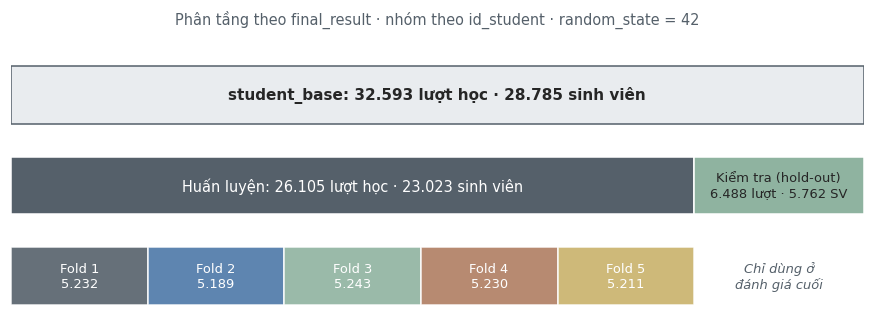

In [8]:
# Hình 4.1: sơ đồ phương án chia (số liệu trên student_base).
n_total = len(base)
n_test = int((datasets['student_base']['split'] == 'test').sum())
n_train = n_total - n_test
fold_counts = datasets['student_base']['fold'].value_counts().sort_index()
s_train = int((students['split'] == 'train').sum()); s_test = int((students['split'] == 'test').sum())

fig, ax = plt.subplots(figsize=(10, 3.3))
ax.set_xlim(0, 100); ax.set_ylim(0, 3.4); ax.axis('off')
ax.add_patch(Rectangle((0, 2.3), 100, 0.7, facecolor='#e9ecef', edgecolor='#55606a'))
ax.text(50, 2.65, f'student_base: {vn_int(n_total)} lượt học · {vn_int(len(students))} sinh viên',
        ha='center', va='center', fontsize=10, weight='bold')
w_train = 100 * n_train / n_total
ax.add_patch(Rectangle((0, 1.2), w_train, 0.7, facecolor=COLOR['Train'], edgecolor='white'))
ax.add_patch(Rectangle((w_train, 1.2), 100 - w_train, 0.7, facecolor=COLOR['Test'], edgecolor='white'))
ax.text(w_train / 2, 1.55, f'Huấn luyện: {vn_int(n_train)} lượt học · {vn_int(s_train)} sinh viên',
        ha='center', va='center', color='white', fontsize=9.5)
ax.text(w_train + (100 - w_train) / 2, 1.55, f'Kiểm tra (hold-out)\n{vn_int(n_test)} lượt · {vn_int(s_test)} SV',
        ha='center', va='center', fontsize=8.5)
x = 0
for k, cnt in fold_counts.items():
    w = w_train * cnt / n_train
    ax.add_patch(Rectangle((x, 0.1), w, 0.7, facecolor=FOLD_COLORS[k - 1], edgecolor='white', alpha=0.9))
    ax.text(x + w / 2, 0.45, f'Fold {k}\n{vn_int(cnt)}', ha='center', va='center', color='white', fontsize=8.5)
    x += w
ax.text(w_train + (100 - w_train) / 2, 0.45, 'Chỉ dùng ở\nđánh giá cuối', ha='center', va='center',
        fontsize=8.5, style='italic', color='#55606a')
ax.set_title('Phân tầng theo final_result · nhóm theo id_student · random_state = 42', fontsize=9.5, color='#55606a')
save_figure(fig, '4_1_2_split_scheme'); plt.show()

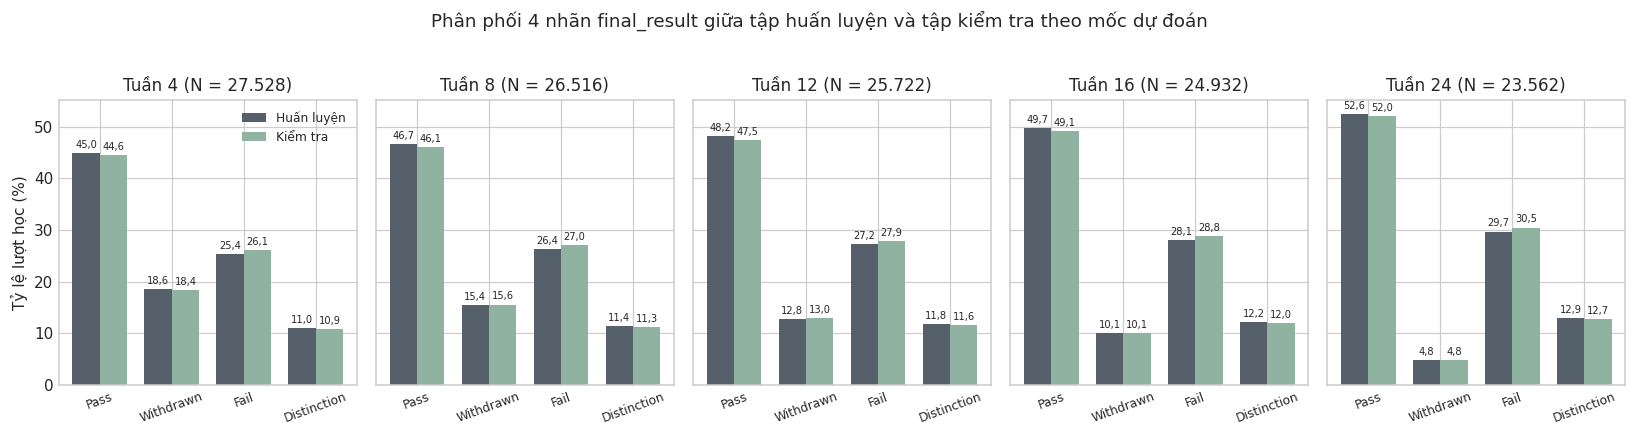

In [9]:
# Hình 4.2: tỷ lệ 4 nhãn ở huấn luyện và kiểm tra theo từng mốc.
fig, axes = plt.subplots(1, len(WEEKS), figsize=(15, 3.8), sharey=True)
x = np.arange(len(LABELS)); width = 0.38
for ax, w in zip(axes, WEEKS):
    sub = label_distribution[label_distribution['Tập dữ liệu'] == f'Tuần {w}'].set_index('Phần dữ liệu')
    for i, (part, key) in enumerate((('Huấn luyện', 'Train'), ('Kiểm tra', 'Test'))):
        vals = [sub.loc[part, f'{lab} (%)'] for lab in LABELS]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, color=COLOR[key], label=part)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.6, f'{v:.1f}'.replace('.', ','),
                    ha='center', va='bottom', fontsize=6.5)
    ax.set_xticks(x, LABELS, fontsize=8, rotation=20)
    n = sub.loc['Toàn bộ', 'Số lượt học']
    ax.set_title(f'Tuần {w} (N = {vn_int(n)})')
axes[0].set_ylabel('Tỷ lệ lượt học (%)')
axes[0].legend(fontsize=8, loc='upper right')
fig.suptitle('Phân phối 4 nhãn final_result giữa tập huấn luyện và tập kiểm tra theo mốc dự đoán', y=1.03)
fig.tight_layout()
save_figure(fig, '4_1_5_label_distribution_by_week'); plt.show()

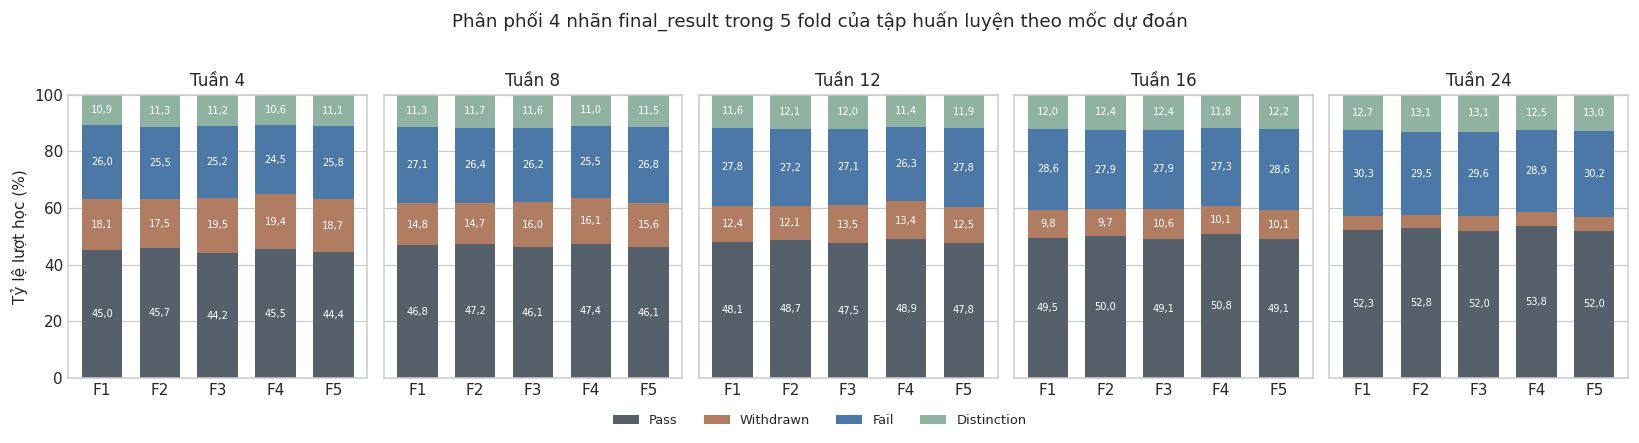

In [10]:
# Hình 4.3: tỷ lệ nhãn trong từng fold (100% stacked) theo từng mốc.
fig, axes = plt.subplots(1, len(WEEKS), figsize=(15, 3.6), sharey=True)
for ax, w in zip(axes, WEEKS):
    sub = label_distribution[(label_distribution['Tập dữ liệu'] == f'Tuần {w}')
                             & label_distribution['Phần dữ liệu'].str.startswith('Fold')]
    bottom = np.zeros(len(sub))
    for lab in LABELS:
        vals = sub[f'{lab} (%)'].to_numpy()
        ax.bar(range(1, N_FOLDS + 1), vals, bottom=bottom, color=LABEL_COLORS[lab], label=lab, width=0.7)
        for k, (v, b0) in enumerate(zip(vals, bottom), start=1):
            if v >= 6:
                ax.text(k, b0 + v / 2, f'{v:.1f}'.replace('.', ','), ha='center', va='center',
                        fontsize=6.5, color='white')
        bottom += vals
    ax.set_xticks(range(1, N_FOLDS + 1), [f'F{k}' for k in range(1, N_FOLDS + 1)])
    ax.set_title(f'Tuần {w}'); ax.set_ylim(0, 100)
axes[0].set_ylabel('Tỷ lệ lượt học (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Phân phối 4 nhãn final_result trong 5 fold của tập huấn luyện theo mốc dự đoán', y=1.02)
fig.tight_layout()
save_figure(fig, '4_1_5_fold_label_distribution'); plt.show()

### 4.1.7. Cách sử dụng phương án chia ở các bước tiếp theo

Các bước 2–6 của tuần 4 dùng hai hàm `load_week_split` và `cv_splits` (định nghĩa trong `src/modeling_pipeline.py`). Tập kiểm tra được tách ra nhưng **không được dùng** cho tới
lần đánh giá cuối cùng; mọi phép biến đổi có học tham số (điền thiếu, One-Hot Encoding, chuẩn hóa, cân bằng lớp)
phải nằm trong `Pipeline` và được fit lại trong từng vòng cross-validation.

In [11]:
from modeling_pipeline import load_week_split, cv_splits   # định nghĩa trong src/modeling_pipeline.py

# Ví dụ kiểm tra nhanh trên mốc tuần 8.
train8, test8 = load_week_split(8)
splits8 = cv_splits(train8)
print(f'Tuần 8: train {len(train8):,} dòng, test {len(test8):,} dòng;',
      'kích thước validation theo fold:', [len(v) for _, v in splits8])
assert set(train8['id_student']).isdisjoint(test8['id_student'])

Tuần 8: train 21,210 dòng, test 5,306 dòng; kích thước validation theo fold: [4291, 4180, 4213, 4277, 4249]


## 4.2. Mã hóa và chuẩn hóa đầu vào

Mục này xây dựng bộ tiền xử lý (`ColumnTransformer`) cho 23 đặc trưng của Chương 3. Các lựa chọn đã thống nhất:

| Nhóm đặc trưng | Phép biến đổi | Học tham số từ dữ liệu? |
| --- | --- | --- |
| 6 biến phân loại (`gender`, `disability`, `region`, `highest_education`, `age_band`, `imd_band`) | One-Hot Encoding với danh mục cố định theo miền giá trị (Phụ lục A, Chương 2–3); biến 2 giá trị giữ 1 cột | Không |
| `late_submission_rate` | Điền trung vị + cột cờ thiếu | **Có** (trung vị) — chỉ fit trên fold huấn luyện |
| 6 cột click (`total_clicks`, `avg_clicks_per_day`, `clicks_*`) | `log1p` = log(1 + x) | Không |
| 10 cột số còn lại và cờ `imd_band_missing` | Giữ nguyên | Không |

**Chưa áp dụng StandardScaler**: việc chuẩn hóa thang đo được quyết định cùng lựa chọn mô hình ở bước sau
(mô hình tuyến tính cần, mô hình cây không cần). Bộ tiền xử lý được viết để có thể thêm bước này mà không đổi các phần khác.

Mọi phân tích mô tả trong mục này chỉ dùng **phần huấn luyện** (`split == train`); tập kiểm tra không được đọc tới.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer

# Danh mục cố định, nhóm cột và hai hàm make_xy / build_preprocessor định nghĩa trong src/modeling_pipeline.py.
from modeling_pipeline import (ALL_FEATURES, CATEGORIES, CAT_COLS, IMPUTE_COLS, LOG_COLS, PASS_COLS, LATE_FLAG,
                               make_xy, build_preprocessor)
FEATURES = list(ALL_FEATURES)   # 23 đặc trưng của Chương 3
assert len(FEATURES) == 23 and set(CAT_COLS + IMPUTE_COLS + LOG_COLS + PASS_COLS) == set(FEATURES)

# Dữ liệu huấn luyện của 5 mốc (tập kiểm tra không được giữ lại trong bộ nhớ).
train_weeks = {w: load_week_split(w)[0] for w in WEEKS}

# Kiểm tra miền giá trị: mọi giá trị phân loại nằm trong danh mục cố định; cột click không âm;
# chỉ late_submission_rate có giá trị thiếu.
for w, df in train_weeks.items():
    for c in CAT_COLS:
        unexpected = set(df[c].dropna().unique()) - set(CATEGORIES[c])
        assert not unexpected and df[c].notna().all(), f'Tuần {w}, {c}: {unexpected}'
    assert (df[LOG_COLS] >= 0).all().all()
    na_cols = [c for c in FEATURES if df[c].isna().any()]
    assert na_cols == ['late_submission_rate'], (w, na_cols)
print('Danh mục phân loại, miền giá trị click và vị trí giá trị thiếu: đạt ở cả 5 mốc')

Danh mục phân loại, miền giá trị click và vị trí giá trị thiếu: đạt ở cả 5 mốc


### 4.2.1. Mã hóa biến phân loại bằng One-Hot Encoding

Mô hình chỉ nhận đầu vào dạng số. Gán số thứ tự cho biến không thứ tự (ví dụ `region`) sẽ tạo quan hệ "lớn hơn"
không có thật. Với ba biến có thứ tự (`highest_education`, `age_band`, `imd_band`), One-Hot cũng được chọn vì
số mức ít, không cần giả định khoảng cách giữa các mức bằng nhau, và nhóm `Unknown` của IMD trở thành một cột riêng
thay vì phải gán một vị trí giả định trong thứ tự.

Danh mục được cố định theo miền giá trị đã khảo sát, nên số cột và thứ tự cột không phụ thuộc vào fold;
`handle_unknown='error'` bảo đảm phát hiện ngay nếu xuất hiện giá trị ngoài danh mục.

In [13]:
ref = train_weeks[8]
category_rows = []
for c in CAT_COLS:
    counts = ref[c].value_counts()
    n_out = 1 if len(CATEGORIES[c]) == 2 else len(CATEGORIES[c])
    category_rows.append({'Đặc trưng': c, 'Có thứ tự': 'Có' if c in ('highest_education', 'age_band', 'imd_band') else 'Không',
                          'Số giá trị': len(CATEGORIES[c]), 'Số cột sau One-Hot': n_out,
                          'Giá trị ít nhất (tuần 8, huấn luyện)': f"{counts.idxmin()} ({counts.min()})"})
category_summary = pd.DataFrame(category_rows)
save_table(category_summary, '4_2_1_onehot_categories')
display(category_summary)
same = (pd.get_dummies(ref['imd_band'])['Unknown'].astype(int).to_numpy() == ref['imd_band_missing'].to_numpy()).all()
comment(f"6 biến phân loại tạo {category_summary['Số cột sau One-Hot'].sum()} cột. Mức hiếm nhất vẫn có hàng trăm "
        "lượt học trong phần huấn luyện tuần 8, đủ để mỗi fold đều có mẫu. "
        + ("Cột `imd_band_Unknown` trùng hoàn toàn với cờ `imd_band_missing` của Chương 3; "
           "việc giữ hay bỏ một trong hai được xem xét ở bước lựa chọn đặc trưng." if same else ''))

,Đặc trưng,Có thứ tự,Số giá trị,Số cột sau One-Hot,"Giá trị ít nhất (tuần 8, huấn luyện)"
0,gender,Không,2,1,F (9510)
1,disability,Không,2,1,Y (1999)
2,region,Không,13,13,Ireland (857)
3,highest_education,Có,5,5,No Formal quals (194)
4,age_band,Có,3,3,55<= (146)
5,imd_band,Có,11,11,Unknown (808)


**Nhận xét:** 6 biến phân loại tạo 34 cột. Mức hiếm nhất vẫn có hàng trăm lượt học trong phần huấn luyện tuần 8, đủ để mỗi fold đều có mẫu. Cột `imd_band_Unknown` trùng hoàn toàn với cờ `imd_band_missing` của Chương 3; việc giữ hay bỏ một trong hai được xem xét ở bước lựa chọn đặc trưng.

### 4.2.2. Xử lý giá trị thiếu của `late_submission_rate`

`late_submission_rate = n_late_submissions / n_submissions_with_due_date`. Khi sinh viên chưa có bài nộp nào có hạn
đến ngày chốt, mẫu số bằng 0 nên tỷ lệ không xác định và Chương 3 giữ giá trị thiếu (không thay bằng 0 vì
"chưa có bài để xét" khác "không nộp muộn"; không điền trung vị vì trung vị là tham số học từ dữ liệu, chỉ được ước
lượng sau khi chia tập). Phần lớn mô hình của scikit-learn không chấp nhận giá trị thiếu nên bước này phải điền.

Bảng và hình dưới đây so sánh nhãn của ba nhóm: tỷ lệ bằng 0, tỷ lệ lớn hơn 0 và giá trị thiếu.

,Mốc dự đoán (tuần),Số lượt học huấn luyện,Số giá trị thiếu,Tỷ lệ thiếu (%),Thiếu do chưa nộp bài nào,Thiếu dù đã nộp (chưa có hạn đến ngày chốt),Tỷ lệ bằng 0 trong số không thiếu (%),Trung vị nhỏ nhất theo vòng CV,Trung vị lớn nhất theo vòng CV
0,4,22042,6448,29.25,6246,202,73.91,0.00,0.00
1,8,21210,3599,16.97,3013,586,66.59,0.00,0.00
2,12,20572,1740,8.46,1710,30,55.96,0.00,0.00
3,16,19950,1575,7.89,1541,34,51.91,0.00,0.00
4,24,18856,1329,7.05,1314,15,44.94,0.25,0.25


,Mốc dự đoán (tuần),Nhóm late_submission_rate,Số lượt học,Pass (%),Withdrawn (%),Fail (%),Distinction (%)
0,4,= 0 (không nộp muộn),11526,52.85,14.79,20.89,11.46
1,4,> 0 (có nộp muộn),4068,38.47,25.96,24.04,11.53
2,4,Thiếu (chưa có bài để xét),6448,34.91,20.92,34.31,9.86
3,8,= 0 (không nộp muộn),11728,54.89,12.45,20.40,12.27
4,8,> 0 (có nộp muộn),5883,41.66,20.36,26.98,11.00
5,8,Thiếu (chưa có bài để xét),3599,28.40,17.14,45.01,9.45
6,12,= 0 (không nộp muộn),10538,56.00,9.57,20.54,13.89
7,12,> 0 (có nộp muộn),8294,46.74,15.29,26.54,11.43
8,12,Thiếu (chưa có bài để xét),1740,7.64,20.52,71.03,0.80
9,16,= 0 (không nộp muộn),9539,57.33,7.18,20.59,14.90


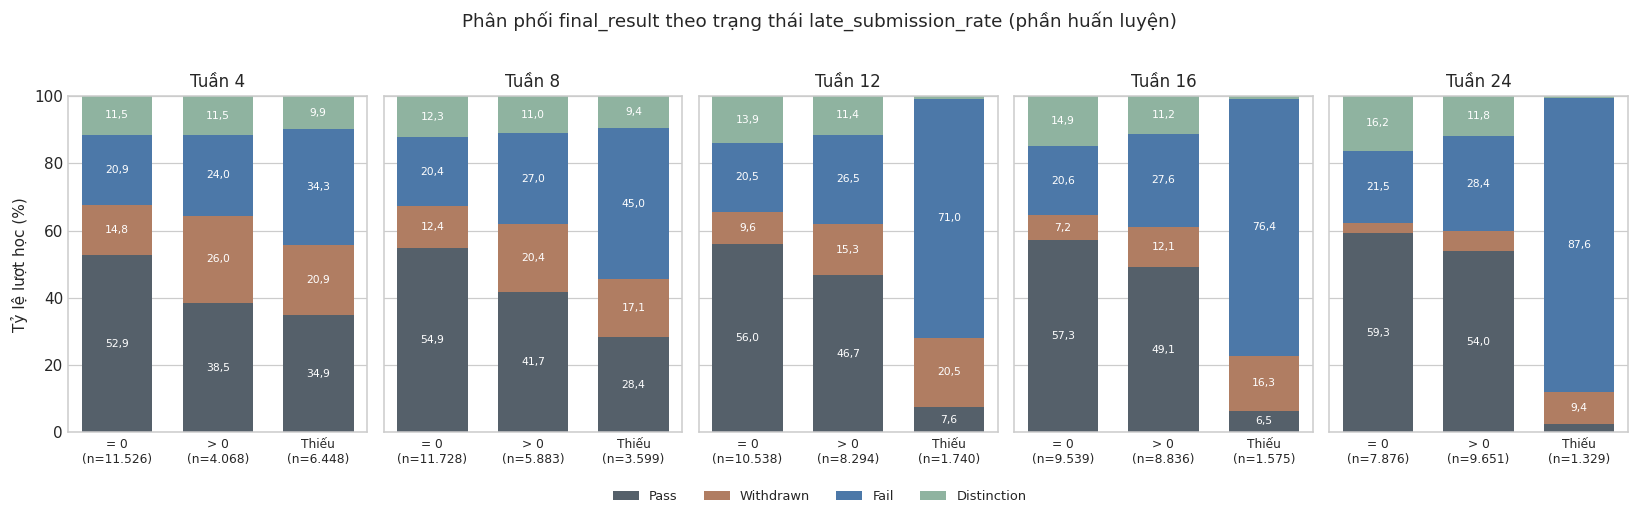

**Nhận xét:** Giá trị thiếu giảm từ 29,25% (tuần 4) xuống 7,05% (tuần 24), chủ yếu do sinh viên chưa nộp bài nào. Nhóm thiếu có tỷ lệ Fail cao nhất (34,3% ở tuần 4, 87,6% ở tuần 24), trong khi nhóm bằng 0 có tỷ lệ Pass cao nhất (52,9% đến 59,3%). Trung vị học trên các vòng CV bằng 0 ở tuần 4 và 0 ở tuần 8, nên nếu chỉ điền trung vị (hoặc 0), nhóm nguy cơ cao nhất sẽ trùng giá trị với nhóm tốt nhất. Vì vậy giá trị thiếu được điền bằng trung vị **kèm cột cờ thiếu**: trung vị chỉ để mô hình nhận được đầu vào số, còn cột cờ giữ thông tin "chưa có bài để xét".

In [14]:
STATUS = ['= 0 (không nộp muộn)', '> 0 (có nộp muộn)', 'Thiếu (chưa có bài để xét)']

def late_status(s):
    out = pd.Series(STATUS[1], index=s.index)
    out[s == 0] = STATUS[0]
    out[s.isna()] = STATUS[2]
    return out

missing_rows, status_rows = [], []
for w, df in train_weeks.items():
    na = df['late_submission_rate'].isna()
    fold_medians = [df.loc[df['fold'] != k, 'late_submission_rate'].median() for k in range(1, N_FOLDS + 1)]
    missing_rows.append({'Mốc dự đoán (tuần)': w, 'Số lượt học huấn luyện': len(df),
                         'Số giá trị thiếu': int(na.sum()), 'Tỷ lệ thiếu (%)': round(100 * na.mean(), 2),
                         'Thiếu do chưa nộp bài nào': int((na & (df['n_submissions'] == 0)).sum()),
                         'Thiếu dù đã nộp (chưa có hạn đến ngày chốt)': int((na & (df['n_submissions'] > 0)).sum()),
                         'Tỷ lệ bằng 0 trong số không thiếu (%)': round(100 * (df.loc[~na, 'late_submission_rate'] == 0).mean(), 2),
                         'Trung vị nhỏ nhất theo vòng CV': min(fold_medians),
                         'Trung vị lớn nhất theo vòng CV': max(fold_medians)})
    assert (na == (df['n_submissions_with_due_date'] == 0)).all()
    status = late_status(df['late_submission_rate'])
    for st in STATUS:
        sub = df[status == st]
        status_rows.append({'Mốc dự đoán (tuần)': w, 'Nhóm late_submission_rate': st, 'Số lượt học': len(sub),
                            **{f'{lab} (%)': round(v, 2) for lab, v in label_pct(sub[TARGET]).items()}})
late_missing = pd.DataFrame(missing_rows)
late_by_status = pd.DataFrame(status_rows)
save_table(late_missing, '4_2_2_late_rate_missing')
save_table(late_by_status, '4_2_2_late_rate_by_status')
display(late_missing, late_by_status)

fig, axes = plt.subplots(1, len(WEEKS), figsize=(15, 4.2), sharey=True)
for ax, w in zip(axes, WEEKS):
    sub = late_by_status[late_by_status['Mốc dự đoán (tuần)'] == w].reset_index(drop=True)
    bottom = np.zeros(len(sub))
    for lab in LABELS:
        vals = sub[f'{lab} (%)'].to_numpy()
        ax.bar(range(3), vals, bottom=bottom, color=LABEL_COLORS[lab], label=lab, width=0.7)
        for i, (v, b0) in enumerate(zip(vals, bottom)):
            if v >= 6:
                ax.text(i, b0 + v / 2, f'{v:.1f}'.replace('.', ','), ha='center', va='center', fontsize=7, color='white')
        bottom += vals
    ax.set_xticks(range(3), [f'= 0\n(n={vn_int(n)})' if i == 0 else (f'> 0\n(n={vn_int(n)})' if i == 1 else f'Thiếu\n(n={vn_int(n)})')
                             for i, n in enumerate(sub['Số lượt học'])], fontsize=8)
    ax.set_title(f'Tuần {w}'); ax.set_ylim(0, 100)
axes[0].set_ylabel('Tỷ lệ lượt học (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.07))
fig.suptitle('Phân phối final_result theo trạng thái late_submission_rate (phần huấn luyện)', y=1.02)
fig.tight_layout()
save_figure(fig, '4_2_2_late_rate_by_status'); plt.show()

fail_na = late_by_status[late_by_status['Nhóm late_submission_rate'] == STATUS[2]].set_index('Mốc dự đoán (tuần)')['Fail (%)']
pass_zero = late_by_status[late_by_status['Nhóm late_submission_rate'] == STATUS[0]].set_index('Mốc dự đoán (tuần)')['Pass (%)']
comment(f"Giá trị thiếu giảm từ {vn_pct(late_missing['Tỷ lệ thiếu (%)'].iloc[0])} (tuần 4) xuống "
        f"{vn_pct(late_missing['Tỷ lệ thiếu (%)'].iloc[-1])} (tuần 24), chủ yếu do sinh viên chưa nộp bài nào. "
        f"Nhóm thiếu có tỷ lệ Fail cao nhất ({vn_pct(fail_na.loc[4], 1)} ở tuần 4, {vn_pct(fail_na.loc[24], 1)} ở tuần 24), "
        f"trong khi nhóm bằng 0 có tỷ lệ Pass cao nhất ({vn_pct(pass_zero.loc[4], 1)} đến {vn_pct(pass_zero.loc[24], 1)}). "
        f"Trung vị học trên các vòng CV bằng {late_missing['Trung vị nhỏ nhất theo vòng CV'].iloc[0]:g} ở tuần 4 và "
        f"{late_missing['Trung vị nhỏ nhất theo vòng CV'].iloc[1]:g} ở tuần 8, nên nếu chỉ điền trung vị (hoặc 0), nhóm nguy cơ cao nhất "
        "sẽ trùng giá trị với nhóm tốt nhất. Vì vậy giá trị thiếu được điền bằng trung vị **kèm cột cờ thiếu**: "
        "trung vị chỉ để mô hình nhận được đầu vào số, còn cột cờ giữ thông tin \"chưa có bài để xét\".")

### 4.2.3. Biến đổi `log1p` cho các đặc trưng số click

Các cột click có đuôi phải rất dài: phần lớn lượt học có vài trăm click nhưng một số ít có hàng nghìn.
`log1p(x) = log(1 + x)` co giãn các giá trị lớn và xác định tại x = 0. Phép biến đổi không loại bỏ hay cắt giá trị
nào (phù hợp quyết định giữ ngoại lai ở Chương 3), không học tham số, và không làm thay đổi kết quả của mô hình cây
vì thứ tự giá trị được bảo toàn.

,Mốc dự đoán (tuần),Cột dữ liệu,Trung vị,Giá trị lớn nhất,Tỷ lệ bằng 0 (%),Độ lệch trước log1p,Độ lệch sau log1p
6,8,total_clicks,303.000000,9481.000000,2.94,3.46,-1.47
7,8,avg_clicks_per_day,5.410714,169.303571,2.94,3.46,-0.02
8,8,clicks_oucontent,39.000000,4134.000000,15.82,3.69,-0.35
9,8,clicks_forumng,52.000000,5607.000000,15.58,7.05,-0.51
10,8,clicks_quiz,15.000000,4041.000000,39.29,5.62,0.14
11,8,clicks_resource,9.000000,4216.000000,12.02,82.46,-0.32


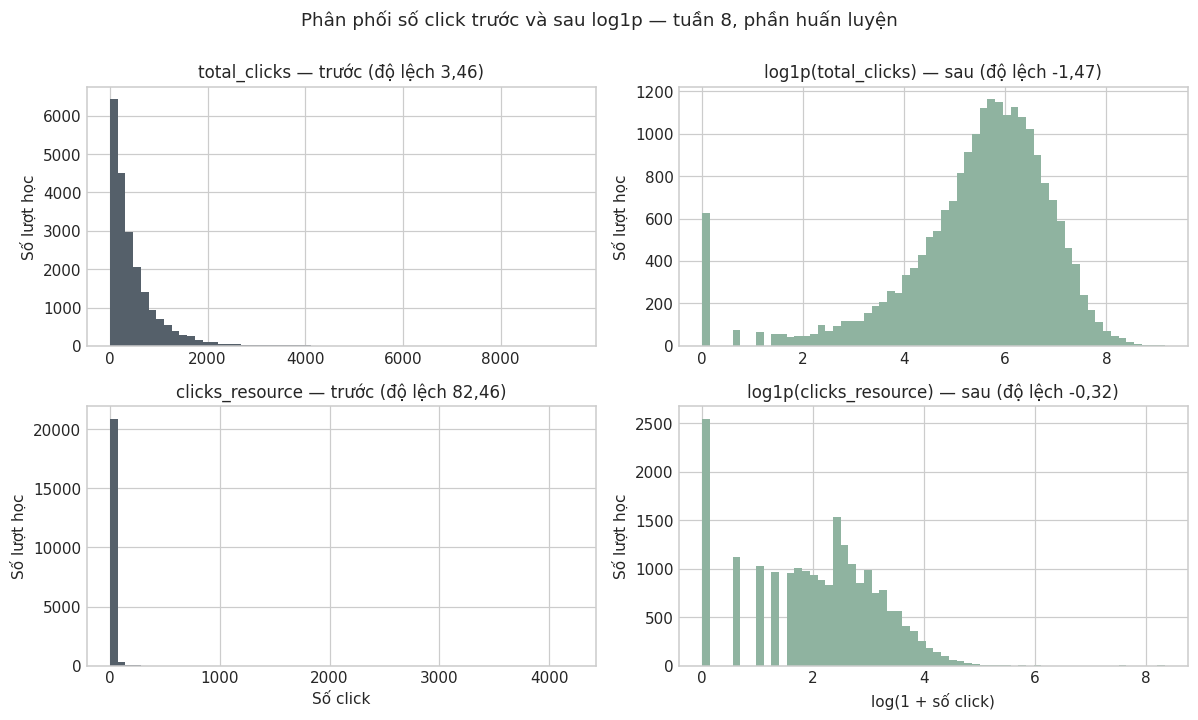

**Nhận xét:** Ở tuần 8, độ lệch của `total_clicks` giảm từ 3,46 xuống -1,47; `clicks_resource` từ 82,46 xuống -0,32. Độ lệch âm sau biến đổi (nếu có) phản ánh nhóm lượt học có giá trị 0 tách khỏi phần còn lại, không phải do phép biến đổi làm mất dữ liệu.

In [15]:
skew_rows = []
for w, df in train_weeks.items():
    for c in LOG_COLS:
        x = df[c].astype(float)
        skew_rows.append({'Mốc dự đoán (tuần)': w, 'Cột dữ liệu': c,
                          'Trung vị': x.median(), 'Giá trị lớn nhất': x.max(),
                          'Tỷ lệ bằng 0 (%)': round(100 * (x == 0).mean(), 2),
                          'Độ lệch trước log1p': round(x.skew(), 2), 'Độ lệch sau log1p': round(np.log1p(x).skew(), 2)})
log_skew = pd.DataFrame(skew_rows)
save_table(log_skew, '4_2_3_log1p_skewness')
display(log_skew[log_skew['Mốc dự đoán (tuần)'] == 8])

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for row, c in enumerate(['total_clicks', 'clicks_resource']):
    x = ref[c].astype(float)
    axes[row, 0].hist(x, bins=60, color=COLOR['Train'])
    axes[row, 0].set_title(f'{c} — trước (độ lệch {x.skew():.2f})'.replace('.', ','))
    axes[row, 1].hist(np.log1p(x), bins=60, color=COLOR['Test'])
    axes[row, 1].set_title(f'log1p({c}) — sau (độ lệch {np.log1p(x).skew():.2f})'.replace('.', ','))
    for ax in axes[row]:
        ax.set_ylabel('Số lượt học')
axes[1, 0].set_xlabel('Số click'); axes[1, 1].set_xlabel('log(1 + số click)')
fig.suptitle('Phân phối số click trước và sau log1p — tuần 8, phần huấn luyện', y=1.0)
fig.tight_layout()
save_figure(fig, '4_2_3_log1p_before_after'); plt.show()
w8 = log_skew[log_skew['Mốc dự đoán (tuần)'] == 8].set_index('Cột dữ liệu')
vn2 = lambda v: f'{v:.2f}'.replace('.', ',')
comment(f"Ở tuần 8, độ lệch của `total_clicks` giảm từ {vn2(w8.loc['total_clicks', 'Độ lệch trước log1p'])} xuống "
        f"{vn2(w8.loc['total_clicks', 'Độ lệch sau log1p'])}; `clicks_resource` từ {vn2(w8.loc['clicks_resource', 'Độ lệch trước log1p'])} "
        f"xuống {vn2(w8.loc['clicks_resource', 'Độ lệch sau log1p'])}. Độ lệch âm sau biến đổi (nếu có) phản ánh nhóm lượt học "
        "có giá trị 0 tách khỏi phần còn lại, không phải do phép biến đổi làm mất dữ liệu.")

### 4.2.4. Kiểm tra bộ tiền xử lý trong cross-validation

Với mỗi mốc và mỗi vòng, bộ tiền xử lý mới được **fit trên 4 fold** rồi áp dụng cho fold còn lại. Các phép kiểm tra:
số cột và thứ tự cột không đổi; không còn giá trị thiếu; trung vị học được đúng bằng trung vị của phần huấn luyện
của vòng đó (không dùng dữ liệu validation); cột cờ khớp vị trí thiếu ban đầu; `expm1` của cột log trả lại giá trị gốc;
mỗi biến phân loại nhiều mức có đúng một cột bằng 1.

In [16]:
cv_rows, ref_columns = [], None
for w, df in train_weeks.items():
    X, y = make_xy(df, FEATURES)
    for k, (tr, va) in enumerate(cv_splits(df), start=1):
        pre = build_preprocessor(FEATURES)
        X_tr = pre.fit_transform(X.iloc[tr])
        X_va = pre.transform(X.iloc[va])
        cols = list(X_tr.columns)
        ref_columns = ref_columns or cols
        assert cols == ref_columns == list(X_va.columns), 'Cột đầu ra thay đổi giữa các vòng'
        learned = pre.named_transformers_['impute'].statistics_[0]
        assert learned == X.iloc[tr]['late_submission_rate'].median()
        was_na = X.iloc[va]['late_submission_rate'].isna().to_numpy()
        assert ((X_va[LATE_FLAG].to_numpy() == 1) == was_na).all()
        assert (X_va.loc[was_na, 'late_submission_rate'] == learned).all()
        assert np.allclose(np.expm1(X_va[LOG_COLS].to_numpy()), X.iloc[va][LOG_COLS].to_numpy())
        for c in CAT_COLS:
            if len(CATEGORIES[c]) > 2:
                assert (X_va[[f'{c}_{v}' for v in CATEGORIES[c]]].sum(axis=1) == 1).all()
        n_nan = int(X_tr.isna().sum().sum() + X_va.isna().sum().sum())
        assert n_nan == 0
        cv_rows.append({'Mốc dự đoán (tuần)': w, 'Vòng CV (fold validation)': k,
                        'Số dòng fit': len(tr), 'Số dòng validation': len(va),
                        'Số cột đầu vào': X.shape[1], 'Số cột đầu ra': X_tr.shape[1],
                        'Giá trị thiếu sau biến đổi': n_nan,
                        'Trung vị học được (fit)': learned,
                        'Trung vị của fold validation': X.iloc[va]['late_submission_rate'].median(),
                        'Kiểm tra': 'Đạt'})
cv_checks = pd.DataFrame(cv_rows)
save_table(cv_checks, '4_2_4_cv_checks')
display(cv_checks)
comment(f"Cả {len(cv_checks)} lần fit (5 mốc × 5 vòng) đều đạt: {X.shape[1]} đặc trưng đầu vào thành "
        f"{len(ref_columns)} cột số, không còn giá trị thiếu, thứ tự cột giống nhau ở mọi vòng và mọi mốc. "
        "Trung vị được học riêng trên phần fit của từng vòng, không dùng dữ liệu của fold validation hay tập kiểm tra.")

,Mốc dự đoán (tuần),Vòng CV (fold validation),Số dòng fit,Số dòng validation,Số cột đầu vào,Số cột đầu ra,Giá trị thiếu sau biến đổi,Trung vị học được (fit),Trung vị của fold validation,Kiểm tra
0,4,1,17573,4469,23,52,0,0.00,0.00,Đạt
1,4,2,17722,4320,23,52,0,0.00,0.00,Đạt
2,4,3,17647,4395,23,52,0,0.00,0.00,Đạt
3,4,4,17592,4450,23,52,0,0.00,0.00,Đạt
4,4,5,17634,4408,23,52,0,0.00,0.00,Đạt
5,8,1,16919,4291,23,52,0,0.00,0.00,Đạt
6,8,2,17030,4180,23,52,0,0.00,0.00,Đạt
7,8,3,16997,4213,23,52,0,0.00,0.00,Đạt
8,8,4,16933,4277,23,52,0,0.00,0.00,Đạt
9,8,5,16961,4249,23,52,0,0.00,0.00,Đạt


**Nhận xét:** Cả 25 lần fit (5 mốc × 5 vòng) đều đạt: 23 đặc trưng đầu vào thành 52 cột số, không còn giá trị thiếu, thứ tự cột giống nhau ở mọi vòng và mọi mốc. Trung vị được học riêng trên phần fit của từng vòng, không dùng dữ liệu của fold validation hay tập kiểm tra.

### 4.2.5. Danh mục cột đầu ra

Bảng liệt kê từng cột sau tiền xử lý và đặc trưng gốc tương ứng, phục vụ diễn giải mô hình ở các bước sau.

In [17]:
pre_full = build_preprocessor(FEATURES).fit(train_weeks[8][FEATURES])   # chỉ để lấy tên cột; không lưu tham số
source_of, method_of = {}, {}
for c in CAT_COLS:
    for v in CATEGORIES[c]:
        source_of[f'{c}_{v}'], method_of[f'{c}_{v}'] = c, 'One-Hot'
source_of['late_submission_rate'], method_of['late_submission_rate'] = 'late_submission_rate', 'Điền trung vị (fit trên huấn luyện)'
source_of[LATE_FLAG], method_of[LATE_FLAG] = 'late_submission_rate', 'Cờ thiếu (1 = ban đầu thiếu)'
for c in LOG_COLS:
    source_of[c], method_of[c] = c, 'log1p'
for c in PASS_COLS:
    source_of[c], method_of[c] = c, 'Giữ nguyên'
out_cols = list(pre_full.get_feature_names_out())
assert out_cols == ref_columns and all(c in source_of for c in out_cols)
output_columns = pd.DataFrame({'STT': range(1, len(out_cols) + 1), 'Cột đầu ra': out_cols,
                               'Đặc trưng gốc': [source_of[c] for c in out_cols],
                               'Phép biến đổi': [method_of[c] for c in out_cols]})
save_table(output_columns, '4_2_5_output_columns')

transform_rows = []
reasons = {
    'One-Hot': 'Biến phân loại; không áp đặt thứ tự hay khoảng cách giữa các mức',
    'Điền trung vị (fit trên huấn luyện)': 'Thiếu có cấu trúc (chưa có bài để xét); trung vị học sau khi chia tập',
    'log1p': 'Phân phối đuôi phải dài; không loại bỏ giá trị',
    'Giữ nguyên': 'Đã là số và không thiếu; chuẩn hóa thang đo quyết định cùng mô hình',
}
for c in FEATURES:
    cols_c = output_columns[output_columns['Đặc trưng gốc'] == c]
    method = 'One-Hot' if c in CAT_COLS else method_of[c]
    transform_rows.append({'Đặc trưng': c, 'Phép biến đổi': method if c not in IMPUTE_COLS else 'Điền trung vị + cờ thiếu',
                           'Học tham số từ dữ liệu': 'Có (trung vị)' if c in IMPUTE_COLS else 'Không',
                           'Số cột đầu ra': len(cols_c), 'Lý do': reasons[method]})
feature_transformations = pd.DataFrame(transform_rows)
save_table(feature_transformations, '4_2_5_feature_transformations')
display(feature_transformations)
display(output_columns.groupby('Phép biến đổi')['Cột đầu ra'].count().rename('Số cột').to_frame())

,Đặc trưng,Phép biến đổi,Học tham số từ dữ liệu,Số cột đầu ra,Lý do
0,gender,One-Hot,Không,1,Biến phân loại; không áp đặt thứ tự hay khoảng...
1,region,One-Hot,Không,13,Biến phân loại; không áp đặt thứ tự hay khoảng...
2,highest_education,One-Hot,Không,5,Biến phân loại; không áp đặt thứ tự hay khoảng...
3,imd_band,One-Hot,Không,11,Biến phân loại; không áp đặt thứ tự hay khoảng...
4,age_band,One-Hot,Không,3,Biến phân loại; không áp đặt thứ tự hay khoảng...
5,num_of_prev_attempts,Giữ nguyên,Không,1,Đã là số và không thiếu; chuẩn hóa thang đo qu...
6,studied_credits,Giữ nguyên,Không,1,Đã là số và không thiếu; chuẩn hóa thang đo qu...
7,disability,One-Hot,Không,1,Biến phân loại; không áp đặt thứ tự hay khoảng...
8,imd_band_missing,Giữ nguyên,Không,1,Đã là số và không thiếu; chuẩn hóa thang đo qu...
9,date_registration,Giữ nguyên,Không,1,Đã là số và không thiếu; chuẩn hóa thang đo qu...


,Số cột
Phép biến đổi,
Cờ thiếu (1 = ban đầu thiếu),1
Giữ nguyên,10
One-Hot,34
log1p,6
Điền trung vị (fit trên huấn luyện),1


### 4.2.6. Cách sử dụng ở các bước tiếp theo

Bộ tiền xử lý luôn được đặt **trong** `Pipeline` cùng mô hình để mỗi vòng cross-validation tự fit lại trên phần
huấn luyện của vòng đó, ví dụ:

```python
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

train_df, _ = load_week_split(8)            # tập kiểm tra chưa dùng
X, y = make_xy(train_df)
model = Pipeline([('pre', build_preprocessor(FEATURES)),
                  # ('scale', StandardScaler()),  # thêm khi dùng mô hình tuyến tính
                  ('clf', ...)])
scores = cross_validate(model, X, y, cv=cv_splits(train_df), scoring='f1_macro')
```

Không fit `build_preprocessor(...)` trên toàn bộ dữ liệu rồi mới chia fold, vì như vậy trung vị của
`late_submission_rate` sẽ chứa thông tin của fold validation.

## 4.3. Khảo sát và lựa chọn đặc trưng

Mục này rà soát 23 đặc trưng theo ba nội dung của kế hoạch: biến ít thông tin, tương quan giữa các đặc trưng số và
nguy cơ rò rỉ. Các quy tắc đã thống nhất:

| Quy tắc | Lựa chọn | Lý do |
| --- | --- | --- |
| Phạm vi danh sách | **Một danh sách chung** cho cả 5 mốc | Mô hình ở các mốc so sánh được với nhau |
| Mức độ loại bỏ | Chỉ loại cột **chắc chắn thừa** (trùng hoàn toàn hoặc tương quan rất cao) | Chỉ 23 đặc trưng trên ~20 nghìn lượt học, không cần giảm chiều; đánh giá theo mô hình để ở bước huấn luyện |
| Ngưỡng tương quan | \|Spearman\| ≥ 0,95 ở **cả 5 mốc** | Đúng tinh thần "chắc chắn thừa"; Spearman dựa trên thứ hạng nên phù hợp dữ liệu lệch |
| Biến ít thông tin | Ghi nhận; **chỉ loại khi gần như độc lập với nhãn ở mọi mốc** (MI < 0,001 và balanced accuracy đơn lẻ ≈ 0,25) | Ít biến động không đồng nghĩa với vô ích; chỉ loại cột không mang thông tin dự đoán |

Mọi phân tích chỉ dùng **phần huấn luyện** của từng mốc; tập kiểm tra không được đọc.

In [18]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

CORR_THRESHOLD = 0.95
CORR_REPORT = 0.80          # các cặp từ ngưỡng này trở lên được liệt kê để báo cáo
NUM_FEATURES = [c for c in FEATURES if c not in CAT_COLS]
FEATURE_GROUP = {c: ('Thông tin nền' if c in CAT_COLS + ['num_of_prev_attempts', 'studied_credits', 'imd_band_missing',
                                                          'date_registration', 'module_presentation_length']
                     else 'Bài nộp' if c.startswith(('n_', 'late_')) else 'VLE') for c in FEATURES}

### 4.3.1. Rà soát biến ít thông tin

Hai đại lượng được dùng: (1) **tỷ lệ giá trị phổ biến nhất** — cột gần như hằng số mang ít thông tin;
(2) **thông tin tương hỗ (mutual information, MI)** giữa từng đặc trưng và `final_result` — MI = 0 nghĩa là
đặc trưng độc lập với nhãn. Biến phân loại và biến đếm ít giá trị được xem là rời rạc; với `late_submission_rate`,
giá trị thiếu được gán −1 **chỉ để tính MI** (thiếu được coi là một trạng thái riêng, đúng như phân tích ở 4.2.2).
Ở cấp cột One-Hot, các mức hiếm được liệt kê riêng.

,Đặc trưng,Nhóm,Tỷ lệ giá trị phổ biến nhất lớn nhất (%),MI nhỏ nhất,MI lớn nhất,Thứ hạng MI (tuần 8)
16,active_days,VLE,5.64,0.0568,0.1627,1
18,avg_clicks_per_day,VLE,4.50,0.0500,0.1408,2
15,total_clicks,VLE,4.50,0.0430,0.1433,3
20,clicks_forumng,VLE,20.76,0.0391,0.0920,4
11,n_submissions,Bài nộp,61.85,0.0162,0.1909,5
17,resource_types_used,VLE,20.46,0.0299,0.0798,6
14,late_submission_rate,Bài nộp,55.29,0.0178,0.1141,7
12,n_submissions_with_due_date,Bài nộp,67.50,0.0125,0.1655,8
19,clicks_oucontent,VLE,20.12,0.0239,0.0597,9
21,clicks_quiz,VLE,53.50,0.0207,0.0558,10


,Đặc trưng,Mức,Tuần 4,Tuần 8,Tuần 12,Tuần 16,Tuần 24,Tỷ lệ nhỏ nhất (%)
0,highest_education,No Formal quals,206,194,184,178,165,0.88
1,highest_education,Post Graduate Qualification,241,232,227,224,210,1.09
2,age_band,55<=,152,146,144,141,133,0.69


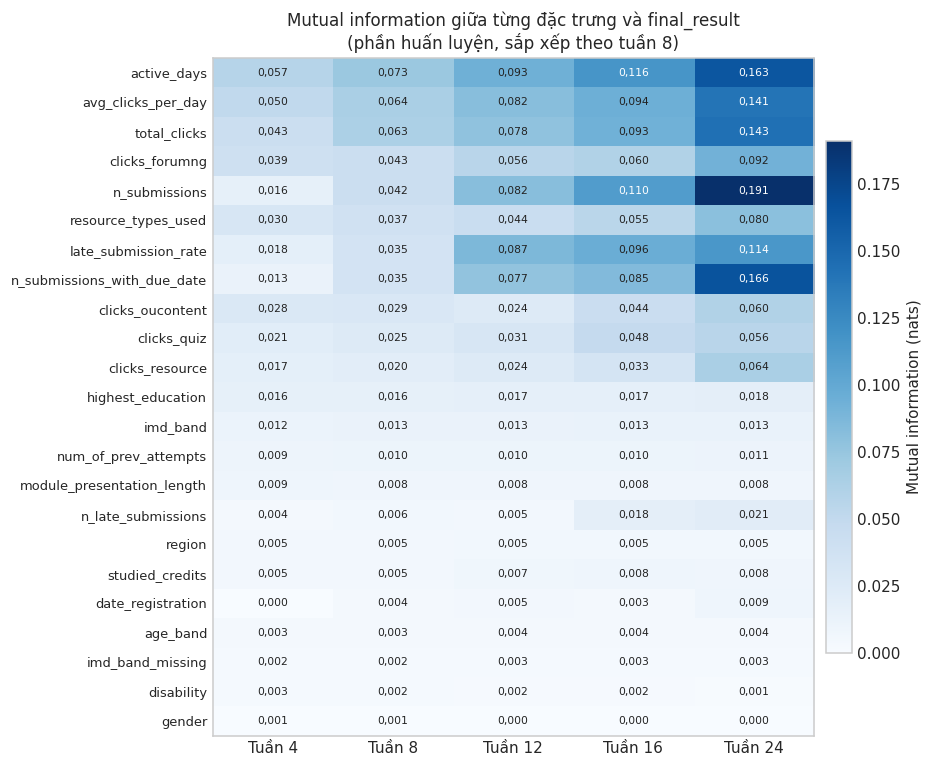

**Nhận xét:** Ba đặc trưng có MI cao nhất ở tuần 8 là `active_days`, `avg_clicks_per_day`, `total_clicks`; nhìn chung nhóm VLE và bài nộp mang nhiều thông tin hơn nhóm thông tin nền, và MI của nhóm hành vi tăng dần theo mốc. Các đặc trưng có MI dưới 0,001 ở mọi mốc: gender. Có 3 mức One-Hot chiếm dưới 2% lượt học; các mức này vẫn có liên quan với nhãn ở cấp biến nên được ghi nhận và không bị loại.

In [19]:
def mi_frame(df):
    X = pd.DataFrame(index=df.index)
    discrete = []
    for c in FEATURES:
        if c in CAT_COLS:
            X[c] = pd.Categorical(df[c], categories=CATEGORIES[c]).codes
            discrete.append(True)
        elif c == 'late_submission_rate':
            X[c] = df[c].fillna(-1.0)
            discrete.append(False)
        else:
            X[c] = df[c].astype(float)
            discrete.append(bool(df[c].nunique() <= 20 and (df[c] % 1 == 0).all()))
    return X, np.array(discrete)

info_rows = []
for w, df in train_weeks.items():
    X_mi, discrete = mi_frame(df)
    mi = mutual_info_classif(X_mi, df[TARGET], discrete_features=discrete, random_state=SEED)
    for c, v, d in zip(FEATURES, mi, discrete):
        top_share = df[c].value_counts(normalize=True, dropna=False).iloc[0] * 100
        info_rows.append({'Mốc dự đoán (tuần)': w, 'Đặc trưng': c, 'Nhóm': FEATURE_GROUP[c],
                          'Số giá trị khác nhau': int(df[c].nunique(dropna=False)),
                          'Tỷ lệ giá trị phổ biến nhất (%)': round(top_share, 2),
                          'Xử lý như biến rời rạc': 'Có' if d else 'Không',
                          'Mutual information': round(float(v), 4)})
info_long = pd.DataFrame(info_rows)
save_table(info_long, '4_3_1_information_by_week')

mi_wide = info_long.pivot(index='Đặc trưng', columns='Mốc dự đoán (tuần)', values='Mutual information').loc[FEATURES]
top_wide = info_long.pivot(index='Đặc trưng', columns='Mốc dự đoán (tuần)', values='Tỷ lệ giá trị phổ biến nhất (%)').loc[FEATURES]
info_summary = pd.DataFrame({'Đặc trưng': FEATURES, 'Nhóm': [FEATURE_GROUP[c] for c in FEATURES],
                             'Tỷ lệ giá trị phổ biến nhất lớn nhất (%)': top_wide.max(axis=1).values,
                             'MI nhỏ nhất': mi_wide.min(axis=1).values, 'MI lớn nhất': mi_wide.max(axis=1).values})
info_summary['Thứ hạng MI (tuần 8)'] = mi_wide[8].rank(ascending=False).astype(int).values
save_table(info_summary, '4_3_1_information_summary')
display(info_summary.sort_values('Thứ hạng MI (tuần 8)'))

# Mức One-Hot hiếm (cấp cột sau mã hóa), tính trên phần huấn luyện của từng mốc.
rare_rows = []
for c in CAT_COLS:
    for v in CATEGORIES[c]:
        counts = {w: int((df[c] == v).sum()) for w, df in train_weeks.items()}
        share = min(100 * counts[w] / len(train_weeks[w]) for w in WEEKS)
        if share < 2:
            rare_rows.append({'Đặc trưng': c, 'Mức': v, **{f'Tuần {w}': counts[w] for w in WEEKS},
                              'Tỷ lệ nhỏ nhất (%)': round(share, 2)})
rare_levels = pd.DataFrame(rare_rows)
save_table(rare_levels, '4_3_1_rare_levels')
display(rare_levels)

fig, ax = plt.subplots(figsize=(7.5, 8))
order = mi_wide[8].sort_values(ascending=False).index
im = ax.imshow(mi_wide.loc[order].to_numpy(), cmap='Blues', aspect='auto')
ax.set_xticks(range(len(WEEKS)), [f'Tuần {w}' for w in WEEKS])
ax.set_yticks(range(len(order)), order, fontsize=8.5)
vmax = mi_wide.to_numpy().max()
for i, c in enumerate(order):
    for j, w in enumerate(WEEKS):
        v = mi_wide.loc[c, w]
        ax.text(j, i, f'{v:.3f}'.replace('.', ','), ha='center', va='center', fontsize=7,
                color='white' if v > vmax * 0.55 else '#222')
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Mutual information (nats)')
ax.set_title('Mutual information giữa từng đặc trưng và final_result\n(phần huấn luyện, sắp xếp theo tuần 8)')
ax.grid(False)
save_figure(fig, '4_3_1_mutual_information'); plt.show()

near_zero = info_summary[info_summary['MI lớn nhất'] < 0.001]['Đặc trưng'].tolist()
top3 = list(order[:3])
comment(f"Ba đặc trưng có MI cao nhất ở tuần 8 là {', '.join(f'`{c}`' for c in top3)}; nhìn chung nhóm VLE và bài nộp "
        "mang nhiều thông tin hơn nhóm thông tin nền, và MI của nhóm hành vi tăng dần theo mốc. "
        + (f"Các đặc trưng có MI dưới 0,001 ở mọi mốc: {', '.join(near_zero)}. " if near_zero else
           "Không đặc trưng nào có MI xấp xỉ 0 ở mọi mốc. ")
        + f"Có {len(rare_levels)} mức One-Hot chiếm dưới 2% lượt học; các mức này vẫn có liên quan với nhãn ở cấp biến "
        "nên được ghi nhận và không bị loại.")

### 4.3.2. Tương quan giữa các đặc trưng số và cột trùng lặp

Ma trận tương quan Spearman được tính trên 17 cột số ở cấp đặc trưng gốc (16 đặc trưng số và cờ thiếu của
`late_submission_rate`, tức cột được thêm ở bước 4.2), riêng cho từng mốc. Spearman không đổi khi áp dụng `log1p`
nên kết quả giống nhau trước và sau biến đổi. Ngoài ra, các cột sau mã hóa được so sánh trực tiếp để tìm cặp
**trùng hoàn toàn**.

,Đặc trưng 1,Đặc trưng 2,Tuần 4,Tuần 8,Tuần 12,Tuần 16,Tuần 24,"Số mốc |r| ≥ 0,95",Vượt ngưỡng ở cả 5 mốc
0,total_clicks,avg_clicks_per_day,1.000,1.000,1.000,1.000,1.000,5,Có
1,n_late_submissions,late_submission_rate,0.993,0.973,0.963,0.933,0.913,3,Không
2,n_submissions_with_due_date,late_submission_missing,-0.965,-0.720,-0.513,-0.480,-0.452,1,Không
3,n_submissions,n_submissions_with_due_date,0.918,0.920,0.822,0.881,0.818,0,Không
4,total_clicks,active_days,0.872,0.895,0.900,0.902,0.909,0,Không
5,active_days,avg_clicks_per_day,0.872,0.895,0.900,0.902,0.909,0,Không
6,n_submissions,late_submission_missing,-0.890,-0.662,-0.498,-0.473,-0.447,0,Không
7,total_clicks,clicks_forumng,0.802,0.819,0.803,0.798,0.790,0,Không
8,avg_clicks_per_day,clicks_forumng,0.802,0.819,0.803,0.798,0.790,0,Không


,Mốc dự đoán (tuần),Cột 1,Cột 2
0,4,imd_band_Unknown,imd_band_missing
1,8,imd_band_Unknown,imd_band_missing
2,12,imd_band_Unknown,imd_band_missing
3,16,imd_band_Unknown,imd_band_missing
4,24,imd_band_Unknown,imd_band_missing


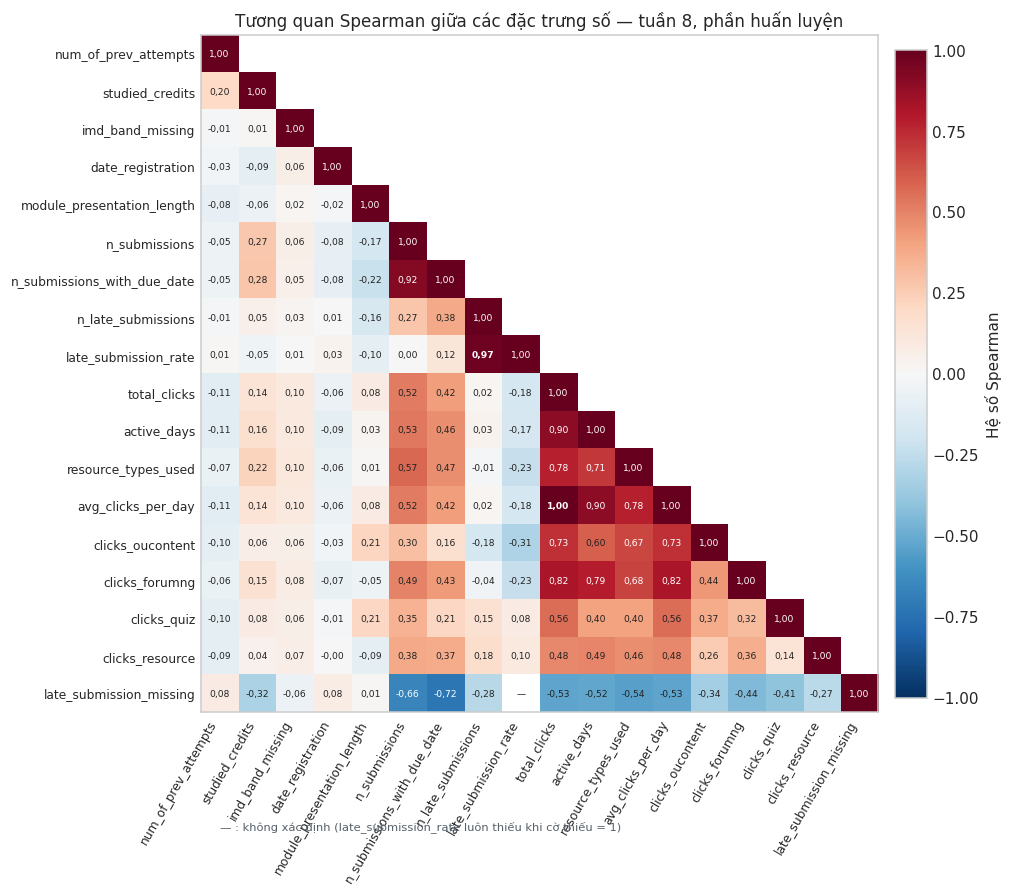

**Nhận xét:** Chỉ 1 cặp vượt |r| ≥ 0,95 ở cả 5 mốc: `total_clicks`–`avg_clicks_per_day`. 2 cặp chỉ vượt ngưỡng ở một số mốc (`n_late_submissions`–`late_submission_rate` (3/5 mốc), `n_submissions_with_due_date`–`late_submission_missing` (1/5 mốc)) nên được giữ theo quy tắc chung. Sau mã hóa có 1 cặp cột trùng hoàn toàn ở mọi mốc: `imd_band_Unknown`–`imd_band_missing`.

In [20]:
CORR_COLS = NUM_FEATURES + ['late_submission_missing']

def corr_frame(df):
    X = df[NUM_FEATURES].astype(float).copy()
    X['late_submission_missing'] = df['late_submission_rate'].isna().astype(float)
    return X.corr(method='spearman')

corr_by_week = {w: corr_frame(df) for w, df in train_weeks.items()}
pair_rows = []
for i, a in enumerate(CORR_COLS):
    for b in CORR_COLS[i + 1:]:
        vals = {w: corr_by_week[w].loc[a, b] for w in WEEKS}
        if max(abs(v) for v in vals.values()) >= CORR_REPORT:
            above_all = all(abs(v) >= CORR_THRESHOLD for v in vals.values())
            n_above = sum(abs(v) >= CORR_THRESHOLD for v in vals.values())
            pair_rows.append({'Đặc trưng 1': a, 'Đặc trưng 2': b,
                              **{f'Tuần {w}': round(vals[w], 3) for w in WEEKS},
                              'Số mốc |r| ≥ 0,95': n_above,
                              'Vượt ngưỡng ở cả 5 mốc': 'Có' if above_all else 'Không'})
corr_pairs = (pd.DataFrame(pair_rows)
              .assign(_m=lambda t: t[[f'Tuần {w}' for w in WEEKS]].abs().max(axis=1))
              .sort_values('_m', ascending=False).drop(columns='_m').reset_index(drop=True))
save_table(corr_pairs, '4_3_2_correlated_pairs')
display(corr_pairs)

# Cột trùng hoàn toàn sau mã hóa (so sánh giá trị từng cột trên phần huấn luyện của mỗi mốc).
dup_rows = []
for w, df in train_weeks.items():
    Xt = build_preprocessor(FEATURES).fit_transform(df[FEATURES]).astype(float)
    hashes = {c: pd.util.hash_pandas_object(Xt[c], index=False).sum() for c in Xt.columns}
    cols = list(Xt.columns)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            if hashes[a] == hashes[b] and Xt[a].equals(Xt[b]):
                dup_rows.append({'Mốc dự đoán (tuần)': w, 'Cột 1': a, 'Cột 2': b})
duplicates = pd.DataFrame(dup_rows)
save_table(duplicates, '4_3_2_identical_columns')
display(duplicates)

fig, ax = plt.subplots(figsize=(9.5, 8))
cm = corr_by_week[8].loc[CORR_COLS, CORR_COLS].to_numpy()
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
im = ax.imshow(np.ma.masked_where(mask, cm), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_COLS)), CORR_COLS, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(CORR_COLS)), CORR_COLS, fontsize=8)
for i in range(len(CORR_COLS)):
    for j in range(i + 1):
        v = cm[i, j]
        ax.text(j, i, '—' if np.isnan(v) else f'{v:.2f}'.replace('.', ','), ha='center', va='center', fontsize=6,
                color='white' if abs(v) > 0.6 else '#222', weight='bold' if abs(v) >= CORR_THRESHOLD and i != j else 'normal')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Hệ số Spearman')
ax.set_title('Tương quan Spearman giữa các đặc trưng số — tuần 8, phần huấn luyện')
ax.text(0, len(CORR_COLS) + 2.6, '— : không xác định (late_submission_rate luôn thiếu khi cờ thiếu = 1)', fontsize=7.5, color='#55606a')
save_figure(fig, '4_3_2_spearman_week8'); plt.show()

redundant = corr_pairs[corr_pairs['Vượt ngưỡng ở cả 5 mốc'] == 'Có']
partial = corr_pairs[(corr_pairs['Vượt ngưỡng ở cả 5 mốc'] == 'Không') & (corr_pairs['Số mốc |r| ≥ 0,95'] > 0)]
comment(f"Chỉ {len(redundant)} cặp vượt |r| ≥ 0,95 ở cả 5 mốc: "
        + ', '.join(f"`{r['Đặc trưng 1']}`–`{r['Đặc trưng 2']}`" for _, r in redundant.iterrows()) + ". "
        + (f"{len(partial)} cặp chỉ vượt ngưỡng ở một số mốc ("
           + ', '.join(f"`{r['Đặc trưng 1']}`–`{r['Đặc trưng 2']}` ({r['Số mốc |r| ≥ 0,95']}/5 mốc)" for _, r in partial.iterrows())
           + ") nên được giữ theo quy tắc chung. " if len(partial) else '')
        + f"Sau mã hóa có {duplicates[['Cột 1', 'Cột 2']].drop_duplicates().shape[0]} cặp cột trùng hoàn toàn ở mọi mốc: "
        + ', '.join(f"`{a}`–`{b}`" for a, b in duplicates[['Cột 1', 'Cột 2']].drop_duplicates().itertuples(index=False)) + '.')

### 4.3.3. Rà soát nguy cơ rò rỉ thông tin

Rò rỉ xảy ra khi đặc trưng chứa thông tin chưa thể biết tại ngày chốt (hoặc chứa gián tiếp nhãn). Việc rà soát gồm hai phần:

1. **Định tính** — đối chiếu nguồn và thời điểm biết được của từng đặc trưng với các quy tắc của Chương 3
   (cửa sổ sự kiện [0, t], loại `score`, `date_unregistration`; kiểm tra bất biến khi thay đổi dữ liệu sau mốc — Bảng 39).
2. **Định lượng** — với từng đặc trưng **đơn lẻ**, một cây quyết định nông (độ sâu 3, cân bằng lớp) được đánh giá bằng
   cross-validation 5 fold (bộ mã hóa fit trong từng vòng). Nếu một đặc trưng đơn lẻ dự đoán gần như hoàn hảo
   (balanced accuracy ≥ 0,90 so với mức ngẫu nhiên 0,25 của 4 lớp), đặc trưng đó bị nghi ngờ rò rỉ. Đây là phép
   chẩn đoán, không phải mô hình dự đoán của đề tài.

,Đặc trưng,Nhóm,Thời điểm biết được,Căn cứ,Đánh giá định tính,Balanced accuracy đơn lẻ lớn nhất,Mốc đạt lớn nhất,"Nghi ngờ rò rỉ (≥ 0,90)"
0,gender,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2570,4,Không
1,region,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2726,8,Không
2,highest_education,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.3137,24,Không
3,imd_band,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2913,16,Không
4,age_band,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2815,4,Không
5,num_of_prev_attempts,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2826,16,Không
6,studied_credits,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2900,4,Không
7,disability,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2654,8,Không
8,imd_band_missing,Thông tin nền,Thông tin khi đăng ký học phần,Giả định có sẵn từ đầu đợt học; OULAD không có...,Chấp nhận theo giả định,0.2611,4,Không
9,date_registration,Thông tin nền,Ngày đăng ký ≤ ngày chốt,Chỉ lượt học đã đăng ký đến ngày chốt được chọ...,Hợp lệ,0.2624,4,Không


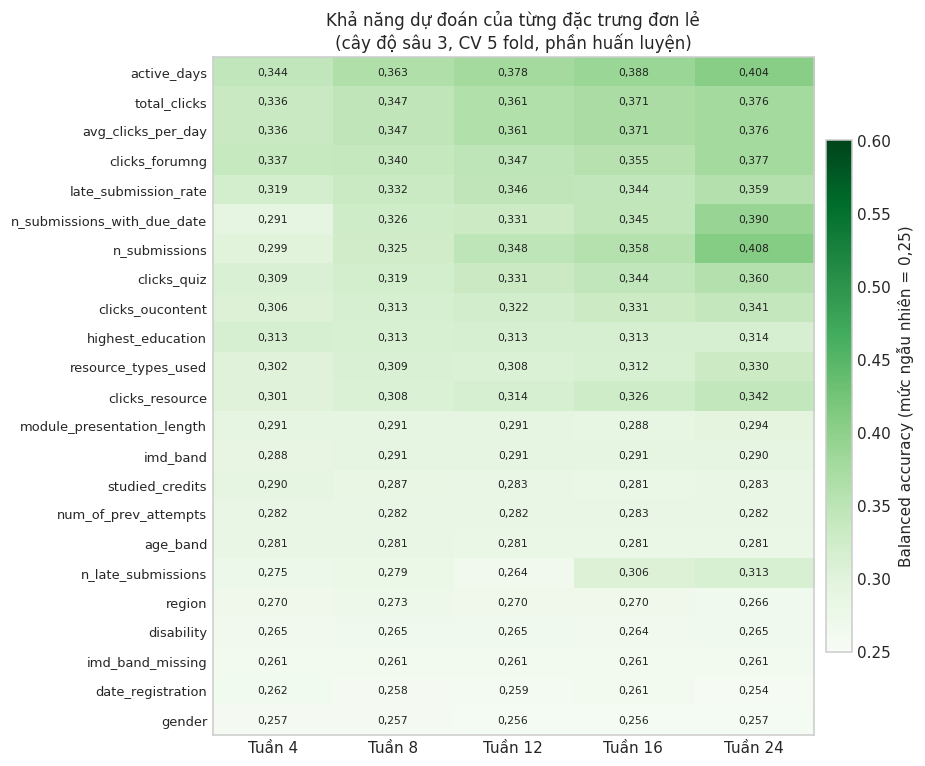

**Nhận xét:** Không đặc trưng đơn lẻ nào đạt ngưỡng nghi ngờ 0,90; cao nhất là `n_submissions` với balanced accuracy 0,41 ở tuần 24 (ngẫu nhiên: 0,25). Các đặc trưng hành vi mạnh dần ở mốc muộn vì cửa sổ quan sát dài hơn, phù hợp với kỳ vọng, không phải dấu hiệu rò rỉ. Về định tính, mọi đặc trưng bài nộp và VLE được tính trong cửa sổ [0, t] và đã qua kiểm tra bất biến của Chương 3; nhóm thông tin nền và thời lượng đợt học được chấp nhận theo giả định có sẵn từ đầu đợt học — giả định này cần được nêu trong báo cáo vì OULAD không cung cấp lịch sử cập nhật.

In [21]:
TIMING = {
    'Thông tin nền': ('Thông tin khi đăng ký học phần', 'Giả định có sẵn từ đầu đợt học; OULAD không có lịch sử cập nhật (Chương 3, 3.1.2)', 'Chấp nhận theo giả định'),
    'date_registration': ('Ngày đăng ký ≤ ngày chốt', 'Chỉ lượt học đã đăng ký đến ngày chốt được chọn (Chương 3, 3.1.2)', 'Hợp lệ'),
    'module_presentation_length': ('Lịch đợt học dự kiến', 'Thời lượng được công bố trước khi đợt học bắt đầu; giả định như thông tin nền', 'Chấp nhận theo giả định'),
    'Bài nộp': ('Sự kiện nộp trong [0, t]', 'Chỉ TMA/CMA, không banked, hạn nộp xác định ≤ t; không dùng score; bất biến khi đổi dữ liệu sau mốc (Bảng 39)', 'Hợp lệ'),
    'VLE': ('Log tương tác trong [0, t]', 'Chỉ log có ngày ≤ t; bất biến khi đổi dữ liệu sau mốc (Bảng 39)', 'Hợp lệ'),
}
leak_rows = []
for c in FEATURES:
    key = c if c in TIMING else FEATURE_GROUP[c]
    when, basis, verdict = TIMING[key]
    leak_rows.append({'Đặc trưng': c, 'Nhóm': FEATURE_GROUP[c], 'Thời điểm biết được': when,
                      'Căn cứ': basis, 'Đánh giá định tính': verdict})
leak_review = pd.DataFrame(leak_rows)

def single_feature_pipeline(c):
    if c in CAT_COLS:
        enc = OneHotEncoder(categories=[CATEGORIES[c]], handle_unknown='error', sparse_output=False)
    elif c in IMPUTE_COLS:
        enc = SimpleImputer(strategy='median', add_indicator=True)
    else:
        enc = 'passthrough'
    return Pipeline([('enc', ColumnTransformer([('f', enc, [c])])),
                     ('tree', DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED))])

single_rows = []
for w, df in train_weeks.items():
    splits = cv_splits(df)
    for c in FEATURES:
        s = cross_val_score(single_feature_pipeline(c), df[[c]], df[TARGET], cv=splits, scoring='balanced_accuracy')
        single_rows.append({'Mốc dự đoán (tuần)': w, 'Đặc trưng': c, 'Balanced accuracy (TB 5 vòng)': round(s.mean(), 4),
                            'Độ lệch chuẩn': round(s.std(), 4)})
single_long = pd.DataFrame(single_rows)
save_table(single_long, '4_3_3_single_feature_scores')
single_wide = single_long.pivot(index='Đặc trưng', columns='Mốc dự đoán (tuần)', values='Balanced accuracy (TB 5 vòng)').loc[FEATURES]
leak_review['Balanced accuracy đơn lẻ lớn nhất'] = single_wide.max(axis=1).values
leak_review['Mốc đạt lớn nhất'] = single_wide.idxmax(axis=1).values
leak_review['Nghi ngờ rò rỉ (≥ 0,90)'] = np.where(leak_review['Balanced accuracy đơn lẻ lớn nhất'] >= 0.90, 'Có', 'Không')
save_table(leak_review, '4_3_3_leakage_review')
display(leak_review)

fig, ax = plt.subplots(figsize=(7.5, 8))
order_s = single_wide[8].sort_values(ascending=False).index
data = single_wide.loc[order_s].to_numpy()
im = ax.imshow(data, cmap='Greens', vmin=0.25, vmax=max(0.6, data.max()), aspect='auto')
ax.set_xticks(range(len(WEEKS)), [f'Tuần {w}' for w in WEEKS])
ax.set_yticks(range(len(order_s)), order_s, fontsize=8.5)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f'{data[i, j]:.3f}'.replace('.', ','), ha='center', va='center', fontsize=7,
                color='white' if data[i, j] > 0.45 else '#222')
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Balanced accuracy (mức ngẫu nhiên = 0,25)')
ax.set_title('Khả năng dự đoán của từng đặc trưng đơn lẻ\n(cây độ sâu 3, CV 5 fold, phần huấn luyện)')
ax.grid(False)
save_figure(fig, '4_3_3_single_feature_scores'); plt.show()

best = single_long.loc[single_long['Balanced accuracy (TB 5 vòng)'].idxmax()]
comment(f"Không đặc trưng đơn lẻ nào đạt ngưỡng nghi ngờ 0,90; cao nhất là `{best['Đặc trưng']}` với balanced accuracy "
        f"{vn2(best['Balanced accuracy (TB 5 vòng)'])} ở tuần {best['Mốc dự đoán (tuần)']} (ngẫu nhiên: 0,25). "
        "Các đặc trưng hành vi mạnh dần ở mốc muộn vì cửa sổ quan sát dài hơn, phù hợp với kỳ vọng, không phải dấu hiệu rò rỉ. "
        "Về định tính, mọi đặc trưng bài nộp và VLE được tính trong cửa sổ [0, t] và đã qua kiểm tra bất biến của Chương 3; "
        "nhóm thông tin nền và thời lượng đợt học được chấp nhận theo giả định có sẵn từ đầu đợt học — giả định này cần "
        "được nêu trong báo cáo vì OULAD không cung cấp lịch sử cập nhật.")

### 4.3.4. Kết quả lựa chọn đặc trưng

Áp dụng các quy tắc ở đầu mục: loại cột trùng hoàn toàn hoặc có |Spearman| ≥ 0,95 ở cả 5 mốc (trong mỗi cặp thừa,
cột được giữ là cột đơn giản, dễ diễn giải hơn), và loại cột gần như độc lập với nhãn ở mọi mốc.

In [22]:
DROP_REASONS = {
    'avg_clicks_per_day': ('Loại', 'Trùng thông tin với total_clicks: Spearman = 1,000 ở cả 5 mốc vì '
                           'avg_clicks_per_day = total_clicks / (ngày chốt + 1) với ngày chốt cố định trong mỗi mốc; '
                           'giữ total_clicks vì đơn giản, dễ diễn giải hơn'),
    'imd_band_missing': ('Loại', 'Trùng hoàn toàn với cột One-Hot imd_band_Unknown ở cả 5 mốc; thông tin thiếu IMD '
                         'vẫn được giữ qua imd_band_Unknown'),
    'gender': ('Loại', 'Gần như độc lập với nhãn ở mọi mốc: MI < 0,001 và balanced accuracy khi dùng riêng ≈ 0,256 '
                       '(ngẫu nhiên 0,25), nên không mang thông tin dự đoán; đồng thời là thuộc tính nhạy cảm, loại bỏ '
                       'giúp giảm rủi ro thiên lệch theo giới tính của hệ thống cảnh báo'),
}
# Xác nhận quyết định khớp với kết quả khảo sát ở 4.3.2.
assert ((redundant['Đặc trưng 1'] == 'total_clicks') & (redundant['Đặc trưng 2'] == 'avg_clicks_per_day')).any() and len(redundant) == 1
assert set(map(frozenset, duplicates[['Cột 1', 'Cột 2']].itertuples(index=False))) == {frozenset({'imd_band_Unknown', 'imd_band_missing'})}
assert (leak_review['Nghi ngờ rò rỉ (≥ 0,90)'] == 'Không').all()
assert near_zero == ['gender'] and single_wide.loc['gender'].max() < 0.26

SELECTED_FEATURES = [c for c in FEATURES if c not in DROP_REASONS]
keep_notes = {
    'n_late_submissions': 'Tương quan cao với late_submission_rate nhưng chỉ vượt 0,95 ở một phần các mốc; giữ theo quy tắc chung',
    'late_submission_rate': 'Tương quan cao với n_late_submissions ở một phần các mốc; giữ theo quy tắc chung; điền trung vị + cờ thiếu (4.2.2)',
    'n_submissions_with_due_date': 'Tương quan cao với cờ thiếu của late_submission_rate chỉ ở tuần 4; giữ',
    'total_clicks': 'Giữ thay cho avg_clicks_per_day (trùng thông tin)',
    'imd_band': 'Giữ; mức Unknown thay vai trò của imd_band_missing',
    'num_of_prev_attempts': 'Phần lớn bằng 0 nhưng vẫn có liên quan với nhãn; ghi nhận, giữ',
}
low_info = set(info_summary.loc[info_summary['Tỷ lệ giá trị phổ biến nhất lớn nhất (%)'] >= 85, 'Đặc trưng'])
selection_rows = []
for c in FEATURES:
    decision, reason = DROP_REASONS.get(c, ('Giữ', keep_notes.get(c, 'Không trùng thông tin, không có dấu hiệu rò rỉ')))
    selection_rows.append({'Đặc trưng': c, 'Nhóm': FEATURE_GROUP[c], 'Quyết định': decision, 'Lý do': reason,
                           'MI (tuần 4–24)': f"{mi_wide.loc[c].min():.4f}–{mi_wide.loc[c].max():.4f}".replace('.', ','),
                           'Ít biến động (giá trị phổ biến ≥ 85%)': 'Có' if c in low_info else 'Không',
                           'Đánh giá rò rỉ': leak_review.set_index('Đặc trưng').loc[c, 'Đánh giá định tính']})
selection = pd.DataFrame(selection_rows)
save_table(selection, '4_3_4_feature_selection')
display(selection)

SELECTION_PATH = PRE_DIR / 'selected_features.json'
SELECTION_PATH.write_text(json.dumps({
    'schema_version': 1,
    'created_at': datetime.now().astimezone().isoformat(timespec='seconds'),
    'source_features': 'data/preprocessed/feature_manifest.json (23 feature_columns)',
    'rules': {'scope': 'one list for all 5 cutoffs',
              'drop_only': 'identical columns or |Spearman| >= 0.95 at all 5 cutoffs (train split only)',
              'low_information': 'reported; removed only if MI < 0.001 at all 5 cutoffs and single-feature balanced accuracy ~ chance (0.25)'},
    'selected_features': SELECTED_FEATURES,
    'dropped_features': {c: r for c, (_, r) in DROP_REASONS.items()},
}, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'{len(FEATURES)} → {len(SELECTED_FEATURES)} đặc trưng; lưu {SELECTION_PATH.relative_to(ROOT).as_posix()}')

,Đặc trưng,Nhóm,Quyết định,Lý do,MI (tuần 4–24),Ít biến động (giá trị phổ biến ≥ 85%),Đánh giá rò rỉ
0,gender,Thông tin nền,Loại,"Gần như độc lập với nhãn ở mọi mốc: MI < 0,001...","0,0003–0,0005",Không,Chấp nhận theo giả định
1,region,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0049–0,0055",Không,Chấp nhận theo giả định
2,highest_education,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0164–0,0179",Không,Chấp nhận theo giả định
3,imd_band,Thông tin nền,Giữ,Giữ; mức Unknown thay vai trò của imd_band_mis...,"0,0119–0,0133",Không,Chấp nhận theo giả định
4,age_band,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0033–0,0037",Không,Chấp nhận theo giả định
5,num_of_prev_attempts,Thông tin nền,Giữ,Phần lớn bằng 0 nhưng vẫn có liên quan với nhã...,"0,0093–0,0107",Có,Chấp nhận theo giả định
6,studied_credits,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0050–0,0084",Không,Chấp nhận theo giả định
7,disability,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0013–0,0025",Có,Chấp nhận theo giả định
8,imd_band_missing,Thông tin nền,Loại,Trùng hoàn toàn với cột One-Hot imd_band_Unkno...,"0,0023–0,0026",Có,Chấp nhận theo giả định
9,date_registration,Thông tin nền,Giữ,"Không trùng thông tin, không có dấu hiệu rò rỉ","0,0000–0,0089",Không,Hợp lệ


23 → 20 đặc trưng; lưu data/preprocessed/selected_features.json


### 4.3.5. Kiểm tra bộ tiền xử lý với danh sách đặc trưng đã chọn

Bộ tiền xử lý của 4.2 được chạy lại với `SELECTED_FEATURES` trên 5 mốc × 5 vòng để xác nhận số cột đầu ra,
không còn giá trị thiếu và không còn cột trùng hoàn toàn.

In [23]:
sel_rows, sel_columns = [], None
for w, df in train_weeks.items():
    X, y = make_xy(df, SELECTED_FEATURES)
    for k, (tr, va) in enumerate(cv_splits(df), start=1):
        pre = build_preprocessor(SELECTED_FEATURES)
        X_tr, X_va = pre.fit_transform(X.iloc[tr]), pre.transform(X.iloc[va])
        sel_columns = sel_columns or list(X_tr.columns)
        assert list(X_tr.columns) == sel_columns == list(X_va.columns)
        assert X_tr.isna().sum().sum() == 0 and X_va.isna().sum().sum() == 0
        assert not X_tr.astype(float).T.duplicated().any(), 'Còn cột trùng hoàn toàn'
        sel_rows.append({'Mốc dự đoán (tuần)': w, 'Vòng CV': k, 'Số đặc trưng đầu vào': X.shape[1],
                         'Số cột đầu ra': X_tr.shape[1], 'Giá trị thiếu sau biến đổi': 0,
                         'Cột trùng hoàn toàn': 0, 'Kiểm tra': 'Đạt'})
selected_checks = pd.DataFrame(sel_rows)
save_table(selected_checks, '4_3_5_selected_checks')
removed_cols = [c for c in ref_columns if c not in sel_columns]
display(selected_checks.groupby('Mốc dự đoán (tuần)')[['Số đặc trưng đầu vào', 'Số cột đầu ra']].first())
comment(f"Danh sách chung gồm {len(SELECTED_FEATURES)} đặc trưng, tạo {len(sel_columns)} cột sau mã hóa "
        f"(trước lựa chọn: {len(FEATURES)} đặc trưng, {len(ref_columns)} cột). Các cột bị loại: "
        + ', '.join(f'`{c}`' for c in removed_cols) + ". Cả 25 lần fit đều đạt; các bước tiếp theo dùng "
        "`make_xy(df, SELECTED_FEATURES)` và `build_preprocessor(SELECTED_FEATURES)`.")

,Số đặc trưng đầu vào,Số cột đầu ra
Mốc dự đoán (tuần),,
4,20,49
8,20,49
12,20,49
16,20,49
24,20,49


**Nhận xét:** Danh sách chung gồm 20 đặc trưng, tạo 49 cột sau mã hóa (trước lựa chọn: 23 đặc trưng, 52 cột). Các cột bị loại: `gender_M`, `avg_clicks_per_day`, `imd_band_missing`. Cả 25 lần fit đều đạt; các bước tiếp theo dùng `make_xy(df, SELECTED_FEATURES)` và `build_preprocessor(SELECTED_FEATURES)`.

## 4.4. Kiểm tra mất cân bằng nhãn và phương án xử lý

Mục này thống kê mức mất cân bằng của 4 lớp, chọn thước đo đánh giá và chuẩn bị 3 phương án xử lý để so sánh ở bước
huấn luyện mô hình. **Không huấn luyện mô hình** ở mục này; hiệu quả của từng phương án được đánh giá ở bước sau.

| Nội dung | Lựa chọn | Lý do |
| --- | --- | --- |
| Thước đo chính | **macro-F1**, kèm balanced accuracy và recall từng lớp | Accuracy che khuất lớp ít; macro-F1 tính mỗi lớp nặng như nhau |
| Phương án 1 | Không xử lý | Mốc so sánh |
| Phương án 2 | Trọng số lớp `class_weight='balanced'` | Không thay đổi dữ liệu, có sẵn trong nhiều mô hình |
| Phương án 3 | Sinh mẫu bằng **SMOTENC**, chỉ trên fold huấn luyện | Phương pháp sinh mẫu phù hợp dữ liệu hỗn hợp số–phân loại |

Các phương pháp sinh mẫu khác không được chọn: SMOTE gốc, Borderline-SMOTE, SVM-SMOTE, ADASYN, KMeans-SMOTE chỉ dành cho
biến số (áp dụng sau One-Hot sẽ tạo giá trị phân loại vô nghĩa); bớt mẫu (undersampling) làm mất dữ liệu thật; mô hình
sinh (CTGAN, TVAE) quá nặng so với nhu cầu.

> Thư viện bổ sung: `imbalanced-learn` (cài trên máy chạy notebook, phiên bản tương thích scikit-learn 1.6). Tệp
> `requirements.txt` của nhóm chưa được chỉnh sửa; cần thống nhất với nhóm trước khi bổ sung.

In [24]:
import time
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight
import imblearn
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

STRATEGIES = mp.STRATEGIES
STRATEGY_NAMES = {'none': 'Không xử lý', 'class_weight': 'Trọng số lớp', 'smotenc': 'SMOTENC'}
SEL_CAT = [c for c in CAT_COLS if c in SELECTED_FEATURES]
SEL_LOG = [c for c in LOG_COLS if c in SELECTED_FEATURES]
SEL_PASS = [c for c in PASS_COLS if c in SELECTED_FEATURES]
SMOTE_CATEGORICAL = SEL_CAT + [LATE_FLAG]      # cờ thiếu là biến 0/1, được xử lý như biến phân loại
INTEGER_COLS = SEL_PASS                        # các cột đếm/ngày vốn là số nguyên
print('imbalanced-learn', imblearn.__version__, '| scikit-learn', sklearn.__version__)

imbalanced-learn 0.13.0 | scikit-learn 1.6.1


### 4.4.1. Thống kê mức mất cân bằng theo mốc

Chỉ số mất cân bằng = số lượt học của lớp lớn nhất / số lượt học của lớp nhỏ nhất, tính trên phần huấn luyện của từng
mốc và trên phần fit (4 fold) của từng vòng cross-validation. Phân phối nhãn của tập kiểm tra đã được trình bày ở 4.1.5.

,Mốc dự đoán (tuần),Số lượt học huấn luyện,Pass,Withdrawn,Fail,Distinction,Pass (%),Withdrawn (%),Fail (%),Distinction (%),Lớp lớn nhất,Lớp nhỏ nhất,Chỉ số mất cân bằng,Chỉ số theo vòng CV (nhỏ nhất),Chỉ số theo vòng CV (lớn nhất)
0,4,22042,9908,4110,5598,2426,44.95,18.65,25.40,11.01,Pass,Distinction,4.08,4.03,4.12
1,8,21210,9910,3275,5599,2426,46.72,15.44,26.40,11.44,Pass,Distinction,4.08,4.04,4.12
2,12,20572,9911,2633,5602,2426,48.18,12.80,27.23,11.79,Pass,Distinction,4.09,4.04,4.12
3,16,19950,9912,2009,5603,2426,49.68,10.07,28.09,12.16,Pass,Withdrawn,4.93,4.88,5.02
4,24,18856,9912,915,5603,2426,52.57,4.85,29.71,12.87,Pass,Withdrawn,10.83,10.70,11.13


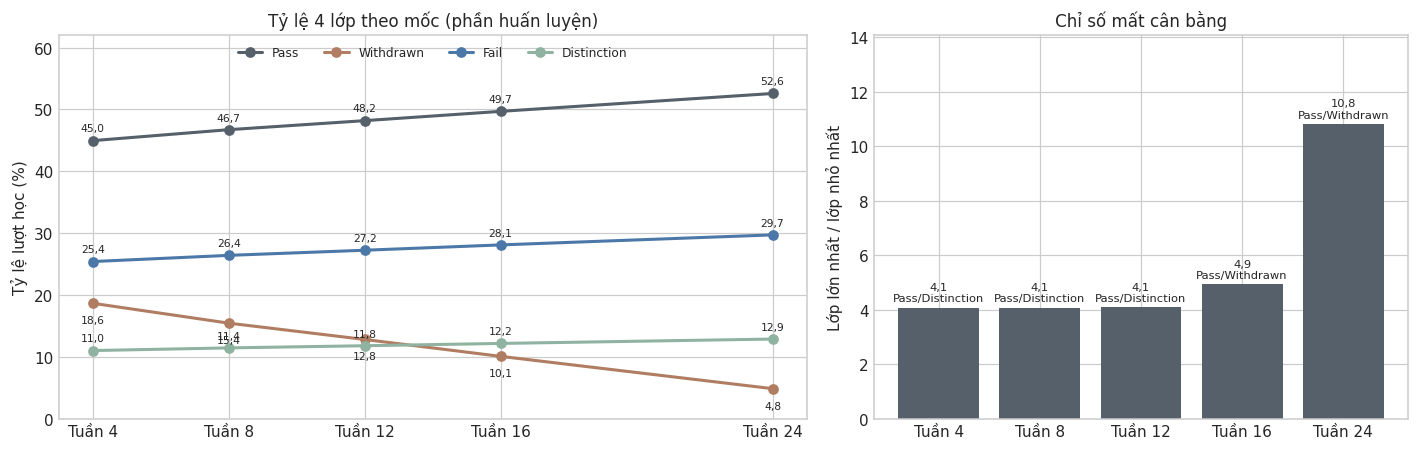

**Nhận xét:** Mức mất cân bằng tăng theo mốc: từ 4,08 lần ở tuần 4 (Pass/Distinction) lên 10,83 lần ở tuần 24 (Pass/Withdrawn). Lớp nhỏ nhất chuyển từ Distinction sang Withdrawn từ tuần 16, trong khi Withdrawn là lớp cần phát hiện sớm. Ở tuần 24 vẫn có 915 lượt học Withdrawn trong phần huấn luyện, nên mức mất cân bằng ở mức vừa phải chứ không thuộc dạng cực đoan. Chỉ số trên từng vòng CV gần với chỉ số của toàn phần huấn luyện, cho thấy phân tầng ở 4.1 giữ được tỷ lệ lớp trong các fold.

In [25]:
imb_rows = []
for w, df in train_weeks.items():
    counts = df[TARGET].value_counts().reindex(LABELS)
    fold_ratios = []
    for k in range(1, N_FOLDS + 1):
        c = df.loc[df['fold'] != k, TARGET].value_counts()
        fold_ratios.append(c.max() / c.min())
    imb_rows.append({'Mốc dự đoán (tuần)': w, 'Số lượt học huấn luyện': len(df),
                     **{f'{lab}': int(counts[lab]) for lab in LABELS},
                     **{f'{lab} (%)': round(100 * counts[lab] / len(df), 2) for lab in LABELS},
                     'Lớp lớn nhất': counts.idxmax(), 'Lớp nhỏ nhất': counts.idxmin(),
                     'Chỉ số mất cân bằng': round(counts.max() / counts.min(), 2),
                     'Chỉ số theo vòng CV (nhỏ nhất)': round(min(fold_ratios), 2),
                     'Chỉ số theo vòng CV (lớn nhất)': round(max(fold_ratios), 2)})
imbalance = pd.DataFrame(imb_rows)
save_table(imbalance, '4_4_1_imbalance')
display(imbalance)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
for lab in LABELS:
    axes[0].plot(WEEKS, imbalance[f'{lab} (%)'], marker='o', color=LABEL_COLORS[lab], label=lab, linewidth=2)
    for w, v in zip(WEEKS, imbalance[f'{lab} (%)']):
        axes[0].annotate(f'{v:.1f}'.replace('.', ','), (w, v), textcoords='offset points',
                         xytext=(0, -13 if lab == 'Withdrawn' else 6), ha='center', fontsize=7)
axes[0].set_xticks(WEEKS, [f'Tuần {w}' for w in WEEKS]); axes[0].set_ylabel('Tỷ lệ lượt học (%)')
axes[0].set_title('Tỷ lệ 4 lớp theo mốc (phần huấn luyện)'); axes[0].legend(fontsize=8, ncol=4, loc='upper center')
axes[0].set_ylim(0, 62)
bars = axes[1].bar([f'Tuần {w}' for w in WEEKS], imbalance['Chỉ số mất cân bằng'], color=COLOR['Train'])
for bar, (_, r) in zip(bars, imbalance.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
                 f"{r['Chỉ số mất cân bằng']:.1f}".replace('.', ',') + f"\n{r['Lớp lớn nhất']}/{r['Lớp nhỏ nhất']}",
                 ha='center', va='bottom', fontsize=7.5)
axes[1].set_ylabel('Lớp lớn nhất / lớp nhỏ nhất'); axes[1].set_ylim(0, imbalance['Chỉ số mất cân bằng'].max() * 1.3)
axes[1].set_title('Chỉ số mất cân bằng')
fig.tight_layout()
save_figure(fig, '4_4_1_imbalance'); plt.show()

r4, r24 = imbalance.iloc[0], imbalance.iloc[-1]
comment(f"Mức mất cân bằng tăng theo mốc: từ {vn2(r4['Chỉ số mất cân bằng'])} lần ở tuần 4 ({r4['Lớp lớn nhất']}/{r4['Lớp nhỏ nhất']}) "
        f"lên {vn2(r24['Chỉ số mất cân bằng'])} lần ở tuần 24 ({r24['Lớp lớn nhất']}/{r24['Lớp nhỏ nhất']}). Lớp nhỏ nhất chuyển từ "
        f"Distinction sang Withdrawn từ tuần {int(imbalance.loc[imbalance['Lớp nhỏ nhất'] == 'Withdrawn', 'Mốc dự đoán (tuần)'].min())}, "
        f"trong khi Withdrawn là lớp cần phát hiện sớm. Ở tuần 24 vẫn có {vn_int(r24['Withdrawn'])} lượt học Withdrawn trong phần "
        "huấn luyện, nên mức mất cân bằng ở mức vừa phải chứ không thuộc dạng cực đoan. Chỉ số trên từng vòng CV gần với "
        "chỉ số của toàn phần huấn luyện, cho thấy phân tầng ở 4.1 giữ được tỷ lệ lớp trong các fold.")

### 4.4.2. Thước đo đánh giá và trọng số lớp

**Thước đo.** Với mất cân bằng như trên, accuracy có thể cao dù mô hình gần như không dự đoán lớp ít (ví dụ luôn đoán
Pass ở tuần 24 đạt accuracy ≈ tỷ lệ Pass). Vì vậy thước đo chính là **macro-F1** (trung bình F1 của 4 lớp, mỗi lớp
cùng trọng số), kèm **balanced accuracy** (trung bình recall các lớp) và **recall từng lớp**, đặc biệt Fail và Withdrawn.

**Trọng số lớp** (`class_weight='balanced'`): trọng số của lớp *c* là $w_c = \dfrac{n}{K \cdot n_c}$, với *n* là số mẫu
huấn luyện, *K* = 4 lớp và $n_c$ là số mẫu của lớp *c*. Trọng số được tính lại trên phần fit của từng vòng CV.

In [26]:
cw_rows = []
for w, df in train_weeks.items():
    y = df[TARGET].to_numpy()
    weights = compute_class_weight('balanced', classes=np.array(LABELS), y=y)
    fold_w = np.array([compute_class_weight('balanced', classes=np.array(LABELS), y=df.loc[df['fold'] != k, TARGET].to_numpy())
                       for k in range(1, N_FOLDS + 1)])
    row = {'Mốc dự đoán (tuần)': w}
    for i, lab in enumerate(LABELS):
        row[f'Trọng số {lab}'] = round(weights[i], 3)
    for i, lab in enumerate(LABELS):
        row[f'{lab}: khoảng theo vòng CV'] = f'{fold_w[:, i].min():.3f}–{fold_w[:, i].max():.3f}'.replace('.', ',')
    row['Trọng số lớn nhất / nhỏ nhất'] = round(weights.max() / weights.min(), 2)
    row['Accuracy nếu luôn đoán lớp lớn nhất (%)'] = round(100 * pd.Series(y).value_counts(normalize=True).max(), 2)
    cw_rows.append(row)
class_weights = pd.DataFrame(cw_rows)
save_table(class_weights, '4_4_2_class_weights')
display(class_weights)

metrics_plan = pd.DataFrame([
    {'Thước đo': 'macro-F1', 'Vai trò': 'Thước đo chính', 'Ý nghĩa': 'Trung bình F1 của 4 lớp; mỗi lớp cùng trọng số'},
    {'Thước đo': 'Balanced accuracy', 'Vai trò': 'Bổ sung', 'Ý nghĩa': 'Trung bình recall của 4 lớp; mức ngẫu nhiên 0,25'},
    {'Thước đo': 'Recall từng lớp (Fail, Withdrawn)', 'Vai trò': 'Bổ sung', 'Ý nghĩa': 'Tỷ lệ sinh viên có nguy cơ được phát hiện'},
    {'Thước đo': 'Accuracy', 'Vai trò': 'Chỉ tham khảo', 'Ý nghĩa': 'Dễ gây hiểu nhầm khi mất cân bằng'},
])
save_table(metrics_plan, '4_4_2_metrics_plan')
c24 = class_weights.iloc[-1]
comment(f"Ở tuần 24, trọng số của Withdrawn là {vn2(c24['Trọng số Withdrawn'])} so với {vn2(c24['Trọng số Pass'])} của Pass "
        f"(gấp {vn2(c24['Trọng số Withdrawn'] / c24['Trọng số Pass'])} lần). Một mô hình luôn đoán Pass đạt accuracy "
        f"{vn_pct(c24['Accuracy nếu luôn đoán lớp lớn nhất (%)'])} nhưng macro-F1 rất thấp và recall Withdrawn bằng 0, "
        "minh họa vì sao accuracy chỉ được dùng để tham khảo.")

,Mốc dự đoán (tuần),Trọng số Pass,Trọng số Withdrawn,Trọng số Fail,Trọng số Distinction,Pass: khoảng theo vòng CV,Withdrawn: khoảng theo vòng CV,Fail: khoảng theo vòng CV,Distinction: khoảng theo vòng CV,Trọng số lớn nhất / nhỏ nhất,Accuracy nếu luôn đoán lớp lớn nhất (%)
0,4,0.556,1.341,0.984,2.271,"0,554–0,558","1,321–1,357","0,976–0,990","2,251–2,288",4.08,44.95
1,8,0.535,1.619,0.947,2.186,"0,533–0,537","1,600–1,638","0,939–0,953","2,166–2,199",4.08,46.72
2,12,0.519,1.953,0.918,2.120,"0,517–0,521","1,928–1,981","0,910–0,923","2,102–2,133",4.09,48.18
3,16,0.503,2.483,0.890,2.056,"0,502–0,506","2,461–2,516","0,884–0,895","2,042–2,066",4.93,49.68
4,24,0.476,5.152,0.841,1.943,"0,474–0,478","5,093–5,278","0,836–0,846","1,930–1,952",10.83,52.57


**Nhận xét:** Ở tuần 24, trọng số của Withdrawn là 5,15 so với 0,48 của Pass (gấp 10,82 lần). Một mô hình luôn đoán Pass đạt accuracy 52,57% nhưng macro-F1 rất thấp và recall Withdrawn bằng 0, minh họa vì sao accuracy chỉ được dùng để tham khảo.

### 4.4.3. Xây dựng pipeline cho 3 phương án

Ba phương án dùng **cùng một chuỗi biến đổi** để kết quả so sánh được với nhau; chỉ khác bước sinh mẫu hoặc trọng số:

1. `prepare` — điền trung vị + cờ thiếu cho `late_submission_rate`; `log1p` cho cột click; các cột số khác chuyển sang
   số thực; biến phân loại giữ dạng nhãn.
2. `smotenc` — **chỉ ở phương án 3**: sinh mẫu cho 3 lớp không phải lớp lớn nhất đến bằng lớp lớn nhất
   (`k_neighbors = 5`). Bước này chỉ chạy khi `fit` (trên phần huấn luyện của vòng CV), không chạy khi đánh giá.
3. `encode` — One-Hot Encoding với danh mục cố định (như 4.2).
4. `clf` — mô hình (bước 6). Ở phương án 2, mô hình được đặt `class_weight='balanced'`.

Thứ tự này là bắt buộc: SMOTENC không nhận giá trị thiếu nên điền thiếu phải đứng trước; SMOTENC cần biến phân loại ở
dạng nhãn gốc nên One-Hot phải đứng sau; nội suy số click trên thang log hợp lý hơn với phân phối lệch.

**Lưu ý kỹ thuật.** Các cột số nguyên được chuyển sang số thực trước SMOTENC. Nếu giữ kiểu số nguyên, `imbalanced-learn`
ép giá trị nội suy về số nguyên bằng cách **cắt phần thập phân** (ví dụ 6,63 bài nộp → 6; −30,26 ngày → −30), làm lệch
có hệ thống về phía 0. Giữ số thực bảo toàn đúng giá trị nội suy của SMOTE.

In [27]:
# to_float, build_prepare_step, build_encode_step, build_imbalance_pipeline: định nghĩa trong src/modeling_pipeline.py.
from modeling_pipeline import to_float, build_prepare_step, build_encode_step, build_imbalance_pipeline

# Kiểm tra: không sinh mẫu thì pipeline mới cho đúng ma trận như build_preprocessor(SELECTED_FEATURES) của 4.3.
equiv_rows = []
for w, df in train_weeks.items():
    X, y = make_xy(df, SELECTED_FEATURES)
    tr, va = cv_splits(df)[0]
    a = build_imbalance_pipeline('none', features=SELECTED_FEATURES).fit(X.iloc[tr], y.iloc[tr]).transform(X.iloc[va])
    b = build_preprocessor(SELECTED_FEATURES).fit(X.iloc[tr]).transform(X.iloc[va])
    assert sorted(a.columns) == sorted(b.columns) and len(a.columns) == len(sel_columns)
    assert np.allclose(a[b.columns].to_numpy(dtype=float), b.to_numpy(dtype=float))
    equiv_rows.append({'Mốc dự đoán (tuần)': w, 'Số cột đầu ra': a.shape[1], 'Khớp với build_preprocessor': 'Đạt'})
display(pd.DataFrame(equiv_rows))

,Mốc dự đoán (tuần),Số cột đầu ra,Khớp với build_preprocessor
0,4,49,Đạt
1,8,49,Đạt
2,12,49,Đạt
3,16,49,Đạt
4,24,49,Đạt


### 4.4.4. Kiểm tra SMOTENC (không huấn luyện mô hình)

Với mỗi mốc và mỗi vòng CV, pipeline phương án 3 (không có mô hình) được fit trên phần huấn luyện của vòng. Các phép
kiểm tra: (1) các dòng gốc được giữ nguyên, mẫu mới chỉ được thêm vào; (2) sau sinh mẫu, 4 lớp có số lượng bằng nhau;
(3) biến phân loại và cờ thiếu của mẫu giả chỉ nhận giá trị hợp lệ; (4) giá trị số của mẫu giả nằm trong khoảng
[nhỏ nhất, lớn nhất] của cùng lớp trong dữ liệu gốc (tính chất nội suy); (5) fold validation **không** bị sinh mẫu —
kết quả biến đổi validation trùng với phương án không xử lý. Tỷ lệ giá trị không nguyên ở các cột đếm/ngày của mẫu giả
được ghi nhận, không làm tròn.

,Mốc dự đoán (tuần),Vòng CV,Số dòng trước,Số dòng sau,Số mẫu sinh thêm,Tỷ lệ mẫu giả (%),Số dòng mỗi lớp sau sinh mẫu,Số dòng validation (không đổi),Thời gian sinh mẫu (giây),Kiểm tra
0,4,1,17573,31592,14019,44.38,7898,4469,2.99,Đạt
1,4,2,17722,31736,14014,44.16,7934,4320,3.22,Đạt
2,4,3,17647,31868,14221,44.62,7967,4395,2.76,Đạt
3,4,4,17592,31532,13940,44.21,7883,4450,2.92,Đạt
4,4,5,17634,31800,14166,44.55,7950,4408,3.05,Đạt
5,8,1,16919,31600,14681,46.46,7900,4291,2.81,Đạt
6,8,2,17030,31744,14714,46.35,7936,4180,2.75,Đạt
7,8,3,16997,31872,14875,46.67,7968,4213,3.12,Đạt
8,8,4,16933,31540,14607,46.31,7885,4277,2.84,Đạt
9,8,5,16961,31804,14843,46.67,7951,4249,2.85,Đạt


Mốc dự đoán (tuần),4,8,12,16,24
Cột dữ liệu,,,,,
active_days,84.41,88.27,89.70,90.78,92.97
date_registration,82.56,85.59,86.98,88.25,90.85
module_presentation_length,37.82,42.13,44.95,46.18,50.09
n_late_submissions,23.36,35.82,47.23,50.59,61.66
n_submissions,34.30,51.75,58.33,65.89,72.87
n_submissions_with_due_date,25.27,39.83,49.14,58.01,65.31
num_of_prev_attempts,17.90,18.53,18.62,19.70,20.55
resource_types_used,75.11,75.06,75.27,75.75,77.41
studied_credits,2.30,2.64,3.03,3.62,5.86


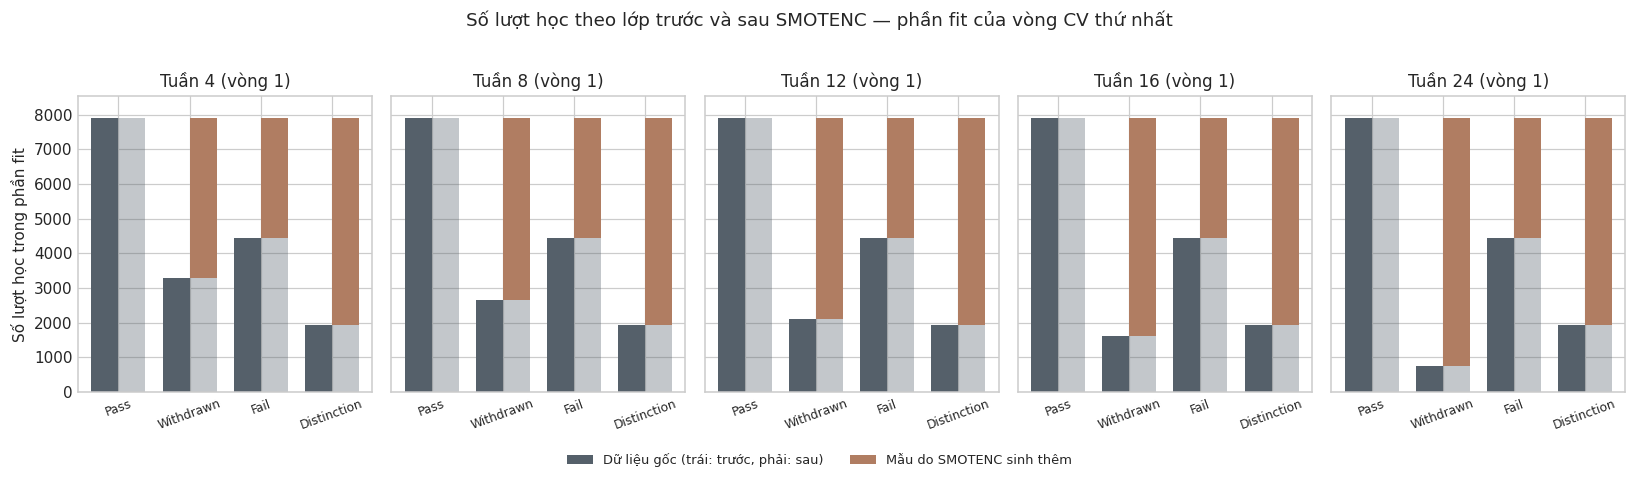

**Nhận xét:** Cả 25 lần sinh mẫu (5 mốc × 5 vòng) đều đạt 5 phép kiểm tra. Mẫu giả chiếm từ 44,16% đến 52,58% dữ liệu sau sinh mẫu; ở tuần 24, lớp Withdrawn tăng từ 732 lên 7.902 lượt học (gấp khoảng 11 lần), tức phần lớn mẫu Withdrawn mà mô hình nhìn thấy là mẫu giả. Phần lớn mẫu giả có giá trị không nguyên ở các cột đếm/ngày (ví dụ số bài nộp lẻ) — đặc điểm vốn có của nội suy SMOTE, được giữ nguyên và cần lưu ý khi diễn giải. Thời gian sinh mẫu mỗi vòng khoảng 2,76 giây.

In [28]:
smote_rows, frac_rows, count_rows = [], [], []
for w, df in train_weeks.items():
    X, y = make_xy(df, SELECTED_FEATURES)
    for k, (tr, va) in enumerate(cv_splits(df), start=1):
        pipe = build_imbalance_pipeline('smotenc')
        prepared = pipe.named_steps['prepare'].fit_transform(X.iloc[tr])
        t0 = time.perf_counter()
        X_res, y_res = clone(pipe.named_steps['smotenc']).fit_resample(prepared, y.iloc[tr])
        elapsed = time.perf_counter() - t0
        n0 = len(prepared)
        # (1) dòng gốc giữ nguyên
        assert X_res.iloc[:n0].reset_index(drop=True).equals(prepared.reset_index(drop=True))
        assert (pd.Series(y_res).iloc[:n0].to_numpy() == y.iloc[tr].to_numpy()).all()
        syn, syn_y = X_res.iloc[n0:], pd.Series(y_res).iloc[n0:].to_numpy()
        # (2) cân bằng
        after = pd.Series(y_res).value_counts().reindex(LABELS)
        before = y.iloc[tr].value_counts().reindex(LABELS)
        assert after.nunique() == 1 and after.iloc[0] == before.max()
        # (3) giá trị phân loại hợp lệ
        for c in SEL_CAT:
            assert syn[c].isin(CATEGORIES[c]).all()
        assert syn[LATE_FLAG].isin([0.0, 1.0]).all()
        # (4) nội suy nằm trong khoảng của cùng lớp
        num_cols = [c for c in prepared.columns if c not in SMOTE_CATEGORICAL]
        for lab in LABELS:
            src = prepared[y.iloc[tr].to_numpy() == lab][num_cols]
            gen = syn[syn_y == lab][num_cols]
            if len(gen):
                assert (gen.min() >= src.min() - 1e-9).all() and (gen.max() <= src.max() + 1e-9).all()
        # (5) validation không bị sinh mẫu
        pipe.fit(X.iloc[tr], y.iloc[tr])
        va_smote = pipe.transform(X.iloc[va])
        va_none = build_imbalance_pipeline('none').fit(X.iloc[tr], y.iloc[tr]).transform(X.iloc[va])
        assert len(va_smote) == len(va) and np.allclose(va_smote.to_numpy(dtype=float), va_none.to_numpy(dtype=float))
        smote_rows.append({'Mốc dự đoán (tuần)': w, 'Vòng CV': k, 'Số dòng trước': n0, 'Số dòng sau': len(X_res),
                           'Số mẫu sinh thêm': len(X_res) - n0,
                           'Tỷ lệ mẫu giả (%)': round(100 * (len(X_res) - n0) / len(X_res), 2),
                           'Số dòng mỗi lớp sau sinh mẫu': int(after.iloc[0]),
                           'Số dòng validation (không đổi)': len(va_smote),
                           'Thời gian sinh mẫu (giây)': round(elapsed, 2), 'Kiểm tra': 'Đạt'})
        for lab in LABELS:
            count_rows.append({'Mốc dự đoán (tuần)': w, 'Vòng CV': k, 'Lớp': lab,
                               'Trước SMOTENC': int(before[lab]), 'Sau SMOTENC': int(after[lab]),
                               'Số mẫu sinh thêm': int(after[lab] - before[lab])})
        if k == 1:
            for c in INTEGER_COLS:
                frac_rows.append({'Mốc dự đoán (tuần)': w, 'Cột dữ liệu': c,
                                  'Tỷ lệ mẫu giả có giá trị không nguyên (%)': round(100 * (syn[c] % 1 != 0).mean(), 2)})
smote_checks = pd.DataFrame(smote_rows)
smote_counts = pd.DataFrame(count_rows)
smote_fractional = pd.DataFrame(frac_rows)
save_table(smote_checks, '4_4_4_smotenc_checks')
save_table(smote_counts, '4_4_4_smotenc_class_counts')
save_table(smote_fractional, '4_4_4_smotenc_fractional')
display(smote_checks)
display(smote_fractional.pivot(index='Cột dữ liệu', columns='Mốc dự đoán (tuần)',
                               values='Tỷ lệ mẫu giả có giá trị không nguyên (%)'))

fig, axes = plt.subplots(1, len(WEEKS), figsize=(15, 3.9), sharey=True)
x = np.arange(len(LABELS)); width = 0.38
for ax, w in zip(axes, WEEKS):
    sub = smote_counts[(smote_counts['Mốc dự đoán (tuần)'] == w) & (smote_counts['Vòng CV'] == 1)].set_index('Lớp').loc[LABELS]
    ax.bar(x - width / 2, sub['Trước SMOTENC'], width, color=COLOR['Train'], label='Dữ liệu gốc')
    ax.bar(x + width / 2, sub['Trước SMOTENC'], width, color=COLOR['Train'], alpha=0.35)
    ax.bar(x + width / 2, sub['Số mẫu sinh thêm'], width, bottom=sub['Trước SMOTENC'], color='#b07d62', label='Mẫu sinh thêm')
    ax.set_xticks(x, LABELS, rotation=20, fontsize=8)
    ax.set_title(f'Tuần {w} (vòng 1)')
    ax.set_ylim(0, sub['Sau SMOTENC'].max() * 1.08)
axes[0].set_ylabel('Số lượt học trong phần fit')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[:1] + handles[-1:], ['Dữ liệu gốc (trái: trước, phải: sau)', 'Mẫu do SMOTENC sinh thêm'],
           loc='lower center', ncol=2, fontsize=8.5, bbox_to_anchor=(0.5, -0.07))
fig.suptitle('Số lượt học theo lớp trước và sau SMOTENC — phần fit của vòng CV thứ nhất', y=1.02)
fig.tight_layout()
save_figure(fig, '4_4_4_smotenc_class_counts'); plt.show()

s24 = smote_checks[smote_checks['Mốc dự đoán (tuần)'] == 24]
wd24 = smote_counts[(smote_counts['Mốc dự đoán (tuần)'] == 24) & (smote_counts['Lớp'] == 'Withdrawn') & (smote_counts['Vòng CV'] == 1)].iloc[0]
comment(f"Cả {len(smote_checks)} lần sinh mẫu (5 mốc × 5 vòng) đều đạt 5 phép kiểm tra. Mẫu giả chiếm từ "
        f"{vn_pct(smote_checks['Tỷ lệ mẫu giả (%)'].min())} đến {vn_pct(smote_checks['Tỷ lệ mẫu giả (%)'].max())} dữ liệu sau "
        f"sinh mẫu; ở tuần 24, lớp Withdrawn tăng từ {vn_int(wd24['Trước SMOTENC'])} lên {vn_int(wd24['Sau SMOTENC'])} lượt học "
        f"(gấp khoảng {wd24['Sau SMOTENC'] / wd24['Trước SMOTENC']:.0f} lần), tức phần lớn mẫu Withdrawn mà mô hình nhìn thấy là "
        "mẫu giả. Phần lớn mẫu giả có giá trị không nguyên ở các cột đếm/ngày (ví dụ số bài nộp lẻ) — đặc điểm vốn có của "
        "nội suy SMOTE, được giữ nguyên và cần lưu ý khi diễn giải. Thời gian sinh mẫu mỗi vòng khoảng "
        f"{vn2(smote_checks['Thời gian sinh mẫu (giây)'].median())} giây.")

### 4.4.5. Tổng hợp phương án và cách sử dụng ở bước huấn luyện

In [29]:
strategies = pd.DataFrame([
    {'Phương án': 'Không xử lý', 'Mã': 'none', 'Cách thực hiện': 'Giữ nguyên phân phối lớp',
     'Ưu điểm': 'Mốc so sánh; xác suất dự đoán phản ánh tần suất thực',
     'Hạn chế': 'Lớp ít (Withdrawn ở mốc muộn) dễ bị bỏ qua'},
    {'Phương án': 'Trọng số lớp', 'Mã': 'class_weight', 'Cách thực hiện': "class_weight='balanced' trong mô hình; w_c = n / (K·n_c), tính lại theo từng vòng",
     'Ưu điểm': 'Không thay đổi dữ liệu, không có mẫu giả; nhanh; có sẵn trong nhiều mô hình',
     'Hạn chế': 'Mô hình không có class_weight phải truyền sample_weight; xác suất dự đoán bị lệch về lớp ít'},
    {'Phương án': 'SMOTENC', 'Mã': 'smotenc', 'Cách thực hiện': 'Sinh mẫu cho 3 lớp không phải lớp lớn nhất đến bằng lớp lớn nhất (k = 5), chỉ trên phần huấn luyện của vòng CV',
     'Ưu điểm': 'Phương pháp sinh mẫu phù hợp dữ liệu hỗn hợp; phổ biến trong nghiên cứu trên OULAD',
     'Hạn chế': 'Mẫu giả không phải sinh viên thật, giá trị đếm không nguyên; xác suất bị lệch; chậm hơn; '
                'cần thư viện imbalanced-learn'},
])
save_table(strategies, '4_4_5_strategies')
display(strategies)

,Phương án,Mã,Cách thực hiện,Ưu điểm,Hạn chế
0,Không xử lý,none,Giữ nguyên phân phối lớp,Mốc so sánh; xác suất dự đoán phản ánh tần suấ...,Lớp ít (Withdrawn ở mốc muộn) dễ bị bỏ qua
1,Trọng số lớp,class_weight,class_weight='balanced' trong mô hình; w_c = n...,"Không thay đổi dữ liệu, không có mẫu giả; nhan...",Mô hình không có class_weight phải truyền samp...
2,SMOTENC,smotenc,Sinh mẫu cho 3 lớp không phải lớp lớn nhất đến...,Phương pháp sinh mẫu phù hợp dữ liệu hỗn hợp; ...,"Mẫu giả không phải sinh viên thật, giá trị đếm..."


Ở bước huấn luyện, mỗi mô hình được đánh giá với cả 3 phương án bằng cùng các fold, ví dụ:

```python
from sklearn.model_selection import cross_validate

train_df, _ = load_week_split(8)                      # tập kiểm tra chưa dùng
X, y = make_xy(train_df, SELECTED_FEATURES)
for strategy in STRATEGIES:
    model = build_imbalance_pipeline(strategy, estimator=...)   # mô hình có tham số class_weight
    scores = cross_validate(model, X, y, cv=cv_splits(train_df),
                            scoring=['f1_macro', 'balanced_accuracy', 'accuracy'])
```

Vì SMOTENC nằm trong `imblearn.pipeline.Pipeline`, mẫu giả chỉ được sinh trên phần huấn luyện của từng vòng; fold
validation và tập kiểm tra luôn là dữ liệu thật.

## 4.5. Hoàn thiện bộ dữ liệu và pipeline cho mô hình hóa

Mục này đóng gói kết quả 4.1–4.4 để bước huấn luyện (và các thành viên khác) dùng trực tiếp:

| Thành phần | Nơi lưu | Ghi chú |
| --- | --- | --- |
| Tập đặc trưng–nhãn theo mốc | `data/modeling/week{N}_train.csv`, `week{N}_test.csv` | Dữ liệu **chưa biến đổi**: khóa, 20 đặc trưng đã chọn, nhãn; tệp train có cột `fold` |
| Quy trình xử lý | `src/modeling_pipeline.py` | Hằng số, hàm đọc dữ liệu, chia fold, tiền xử lý, pipeline 3 phương án |
| Mô tả và kiểm tra | `data/modeling/modeling_manifest.json`, `data/modeling/README.md` | Phiên bản thư viện, số dòng, mã băm SHA-256, kiểu dữ liệu |

Dữ liệu được lưu **trước khi biến đổi** vì trung vị điền thiếu và SMOTENC phải được fit lại trong từng vòng
cross-validation; lưu sẵn ma trận đã biến đổi dễ dẫn đến rò rỉ khi chia fold về sau. Tập huấn luyện và tập kiểm tra
được tách thành hai tệp để tránh dùng nhầm. Pipeline đã fit (`.pkl`) không được lưu ở bước này.

### 4.5.1. Kiểm tra tổng hợp đầu ra sau biến đổi

Pipeline hoàn chỉnh (phương án không sinh mẫu) được fit trên phần huấn luyện của từng vòng và áp dụng cho fold
validation, ở cả 5 mốc. Mỗi ma trận đầu ra được kiểm tra: số cột và thứ tự cột, không có giá trị thiếu hay vô cực,
cột One-Hot và cờ thiếu chỉ nhận 0/1, cột log không âm, nhãn thuộc 4 lớp.

In [30]:
final_rows, final_columns = [], None
for w, df in train_weeks.items():
    X, y = make_xy(df, SELECTED_FEATURES)
    assert set(y.unique()) <= set(LABELS)
    for k, (tr, va) in enumerate(cv_splits(df), start=1):
        pipe = build_imbalance_pipeline('none', features=SELECTED_FEATURES).fit(X.iloc[tr], y.iloc[tr])
        for part, idx in (('fit', tr), ('validation', va)):
            Xt = pipe.transform(X.iloc[idx]).astype(float)
            final_columns = final_columns or list(Xt.columns)
            onehot = [c for c in Xt.columns if any(c == f'{f}_{v}' for f in SEL_CAT for v in CATEGORIES[f])]
            checks = {
                'Cột đúng thứ tự': list(Xt.columns) == final_columns,
                'Không thiếu': not Xt.isna().any().any(),
                'Không vô cực': np.isfinite(Xt.to_numpy()).all(),
                'One-Hot và cờ ∈ {0,1}': Xt[onehot + [LATE_FLAG]].isin([0.0, 1.0]).all().all(),
                'Cột log ≥ 0': (Xt[SEL_LOG] >= 0).all().all(),
            }
            assert all(checks.values()), (w, k, part, checks)
            final_rows.append({'Mốc dự đoán (tuần)': w, 'Vòng CV': k, 'Phần dữ liệu': part,
                               'Số dòng': len(Xt), 'Số cột': Xt.shape[1],
                               **{name: 'Đạt' for name in checks}})
final_checks = pd.DataFrame(final_rows)
save_table(final_checks, '4_5_1_final_checks')
display(final_checks.groupby('Mốc dự đoán (tuần)').agg(**{'Số ma trận kiểm tra': ('Số dòng', 'size'),
                                                         'Số cột': ('Số cột', 'first')}))
comment(f"{len(final_checks)} ma trận đầu ra (5 mốc × 5 vòng × phần fit và validation) đều đạt: {len(final_columns)} cột "
        "theo cùng thứ tự, không có giá trị thiếu hay vô cực, One-Hot và cờ thiếu chỉ nhận 0/1, cột log không âm.")

,Số ma trận kiểm tra,Số cột
Mốc dự đoán (tuần),,
4,10,49
8,10,49
12,10,49
16,10,49
24,10,49


**Nhận xét:** 50 ma trận đầu ra (5 mốc × 5 vòng × phần fit và validation) đều đạt: 49 cột theo cùng thứ tự, không có giá trị thiếu hay vô cực, One-Hot và cờ thiếu chỉ nhận 0/1, cột log không âm.

### 4.5.2. Lưu tập đặc trưng–nhãn tại năm mốc dự đoán

Mỗi tệp gồm: 3 cột khóa lượt học, `prediction_week`, `cutoff_day`, 20 đặc trưng đã chọn (giá trị gốc, chưa biến đổi),
nhãn `final_result`; tệp train có thêm `fold` (1–5). Sau khi ghi, từng tệp được đọc lại để đối chiếu với dữ liệu nguồn.

In [31]:
import platform

MODEL_DATA_DIR = mp.MODEL_DATA_DIR
MODEL_DATA_DIR.mkdir(parents=True, exist_ok=True)
META_COLS = STUDENT_KEY + ['prediction_week', 'cutoff_day']
export_rows = []
for w in WEEKS:
    full_train, full_test = load_week_split(w)
    parts = {'train': full_train[META_COLS + SELECTED_FEATURES + [TARGET, 'fold']],
             'test': full_test[META_COLS + SELECTED_FEATURES + [TARGET]]}
    for part, frame in parts.items():
        path = mp.modeling_path(w, part)
        frame.to_csv(path, index=False, encoding='utf-8')
        back = mp.load_modeling_data(w, part)
        assert list(back.columns) == list(frame.columns) and len(back) == len(frame)
        assert (back[STUDENT_KEY].astype(str).to_numpy() == frame[STUDENT_KEY].astype(str).to_numpy()).all()
        assert (back[TARGET].astype(str).to_numpy() == frame[TARGET].astype(str).to_numpy()).all()
        num = [c for c in SELECTED_FEATURES if c not in CAT_COLS]
        assert np.allclose(back[num].to_numpy(dtype=float), frame[num].to_numpy(dtype=float), equal_nan=True)
        export_rows.append({'Tệp': path.relative_to(ROOT).as_posix(), 'Mốc dự đoán (tuần)': w, 'Phần dữ liệu': part,
                            'Số lượt học': len(back), 'Số sinh viên': back['id_student'].nunique(),
                            'Số cột': back.shape[1], 'Số đặc trưng': len(SELECTED_FEATURES),
                            'Dung lượng (MiB)': round(path.stat().st_size / 2**20, 2),
                            'SHA-256': sha256_file(path)})
    tr_ids = set(full_train['id_student']); te_ids = set(full_test['id_student'])
    assert tr_ids.isdisjoint(te_ids)
exports = pd.DataFrame(export_rows)
# Số dòng phải khớp phương án chia ở 4.1.5.
for w in WEEKS:
    ref_row = split_size.set_index('Tập dữ liệu').loc[f'Tuần {w}']
    got = exports[exports['Mốc dự đoán (tuần)'] == w].set_index('Phần dữ liệu')['Số lượt học']
    assert got['train'] == ref_row['Số lượt học huấn luyện'] and got['test'] == ref_row['Số lượt học kiểm tra']
save_table(exports.drop(columns='SHA-256'), '4_5_2_exports')
display(exports.drop(columns='SHA-256'))

,Tệp,Mốc dự đoán (tuần),Phần dữ liệu,Số lượt học,Số sinh viên,Số cột,Số đặc trưng,Dung lượng (MiB)
0,data/modeling/week4_train.csv,4,train,22042,19879,27,20,2.59
1,data/modeling/week4_test.csv,4,test,5486,4956,26,20,0.63
2,data/modeling/week8_train.csv,8,train,21210,19290,27,20,2.53
3,data/modeling/week8_test.csv,8,test,5306,4822,26,20,0.62
4,data/modeling/week12_train.csv,12,train,20572,18800,27,20,2.53
5,data/modeling/week12_test.csv,12,test,5150,4705,26,20,0.62
6,data/modeling/week16_train.csv,16,train,19950,18381,27,20,2.46
7,data/modeling/week16_test.csv,16,test,4982,4584,26,20,0.60
8,data/modeling/week24_train.csv,24,train,18856,17546,27,20,2.35
9,data/modeling/week24_test.csv,24,test,4706,4391,26,20,0.58


### 4.5.3. Manifest và hướng dẫn sử dụng

Manifest ghi lại nguồn dữ liệu, cấu hình, danh sách cột, kiểu dữ liệu, phiên bản thư viện và mã băm của từng tệp,
để kiểm tra dữ liệu không bị thay đổi và tái lập kết quả.

In [32]:
manifest_model = {
    'schema_version': 1,
    'created_at': datetime.now().astimezone().isoformat(timespec='seconds'),
    'created_by': 'modeling_prep.ipynb (Chương 4, mục 4.5)',
    'environment': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__},
    'sources': {p: sha256_file(ROOT / p) for p in ['data/preprocessed/split_assignment.csv',
                                                   'data/preprocessed/selected_features.json',
                                                   'data/preprocessed/feature_manifest.json',
                                                   *[f'data/preprocessed/oulad_week{w}.csv' for w in WEEKS],
                                                   'src/modeling_pipeline.py']},
    'observation_unit': STUDENT_KEY,
    'target_column': TARGET, 'target_labels': LABELS,
    'metadata_columns': ['prediction_week', 'cutoff_day'],
    'feature_columns': SELECTED_FEATURES,
    'fold_column': 'fold (train only, 1..5; grouped by id_student, stratified by final_result)',
    'csv_dtypes': {c: str(t) for c, t in mp.load_modeling_data(WEEKS[0], 'train').dtypes.items()},
    'values_are_raw': 'Features are NOT transformed. Use modeling_pipeline.build_imbalance_pipeline inside CV.',
    'transformed_columns': final_columns,
    'imbalance_strategies': STRATEGIES,
    'primary_metric': 'f1_macro (plus balanced_accuracy and per-class recall)',
    'test_policy': 'week{N}_test.csv is reserved for the final evaluation only.',
    'files': exports.to_dict(orient='records'),
}
(MODEL_DATA_DIR / 'modeling_manifest.json').write_text(
    json.dumps(manifest_model, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

readme = f'''# Dữ liệu cho mô hình hóa (tuần 4)

Được tạo bởi `modeling_prep.ipynb` (mục 4.5). Không chỉnh sửa thủ công; chạy lại notebook nếu cần tạo lại.

| Tệp | Nội dung |
| --- | --- |
| `week{{N}}_train.csv` | Phần huấn luyện tại mốc tuần N (N = 4, 8, 12, 16, 24); cột `fold` = 1..5 cho cross-validation |
| `week{{N}}_test.csv` | Tập kiểm tra tại mốc tuần N — **chỉ dùng cho lần đánh giá cuối cùng** |
| `modeling_manifest.json` | Cấu hình, kiểu dữ liệu, phiên bản thư viện, số dòng và SHA-256 của từng tệp |

- Mỗi dòng là một lượt học (`code_module`, `code_presentation`, `id_student`); nhãn `final_result` gồm 4 lớp.
- {len(SELECTED_FEATURES)} đặc trưng ở dạng **giá trị gốc, chưa biến đổi**. Điền thiếu, log1p, One-Hot và SMOTENC
  nằm trong pipeline của `src/modeling_pipeline.py` và phải được fit lại trong từng vòng cross-validation.
- Một sinh viên chỉ thuộc tập huấn luyện hoặc tập kiểm tra, và chỉ thuộc một fold, ở cả 5 mốc.

```python
import sys; sys.path.insert(0, 'src')          # chạy từ thư mục oulad_project/
import modeling_pipeline as mp
from sklearn.model_selection import cross_validate

train_df = mp.load_modeling_data(8, 'train')
X, y = mp.make_xy(train_df)
model = mp.build_imbalance_pipeline('class_weight', estimator=...)   # 'none' | 'class_weight' | 'smotenc'
scores = cross_validate(model, X, y, cv=mp.cv_splits(train_df), scoring=['f1_macro', 'balanced_accuracy'])
```

Cần các thư viện: pandas, numpy, scikit-learn {sklearn.__version__}, imbalanced-learn {imblearn.__version__}.
'''
(MODEL_DATA_DIR / 'README.md').write_text(readme, encoding='utf-8')
print([p.name for p in sorted(MODEL_DATA_DIR.iterdir())])

['modeling_manifest.json', 'README.md', 'week12_test.csv', 'week12_train.csv', 'week16_test.csv', 'week16_train.csv', 'week24_test.csv', 'week24_train.csv', 'week4_test.csv', 'week4_train.csv', 'week8_test.csv', 'week8_train.csv']


### 4.5.4. Kiểm tra khả năng tái sử dụng

Kiểm tra quy trình như một người dùng mới: chỉ đọc tệp `data/modeling/` và dùng hàm trong `src/modeling_pipeline.py`
(không dùng biến của notebook). Kết quả phải trùng với kết quả trong notebook; pipeline của cả 3 phương án phải
tạo được, fit được trên phần huấn luyện của một vòng và lưu được bằng `pickle` (cần cho việc lưu mô hình ở bước sau).

In [33]:
import importlib
import pickle
mp = importlib.reload(mp)
reuse_rows = []
for w in WEEKS:
    tr_df = mp.load_modeling_data(w, 'train')
    X_m, y_m = mp.make_xy(tr_df)
    assert list(X_m.columns) == SELECTED_FEATURES and mp.load_selected_features() == SELECTED_FEATURES
    splits_m = mp.cv_splits(tr_df)
    ref_df = train_weeks[w]
    assert [len(v) for _, v in splits_m] == [len(v) for _, v in cv_splits(ref_df)]
    tr, va = splits_m[0]
    a = mp.build_imbalance_pipeline('none').fit(X_m.iloc[tr], y_m.iloc[tr]).transform(X_m.iloc[va])
    X_r, y_r = make_xy(ref_df, SELECTED_FEATURES)
    tr_r, va_r = cv_splits(ref_df)[0]
    b = build_imbalance_pipeline('none', features=SELECTED_FEATURES).fit(X_r.iloc[tr_r], y_r.iloc[tr_r]).transform(X_r.iloc[va_r])
    same = list(a.columns) == list(b.columns) and np.allclose(a.to_numpy(dtype=float), b.to_numpy(dtype=float))
    assert same
    picklable = all(len(pickle.dumps(mp.build_imbalance_pipeline(s))) > 0 for s in mp.STRATEGIES)
    reuse_rows.append({'Mốc dự đoán (tuần)': w, 'Số dòng train': len(tr_df), 'Số đặc trưng': X_m.shape[1],
                       'Số cột sau biến đổi': a.shape[1], 'Trùng kết quả notebook': 'Đạt',
                       'Pipeline 3 phương án lưu được (pickle)': 'Đạt' if picklable else 'Không'})
# Fit thử pipeline SMOTENC từ module trên một vòng (không có mô hình) và lưu bằng pickle.
smote_pipe = mp.build_imbalance_pipeline('smotenc').fit(X_m.iloc[tr], y_m.iloc[tr])
assert len(pickle.loads(pickle.dumps(smote_pipe)).transform(X_m.iloc[va])) == len(va)
reuse = pd.DataFrame(reuse_rows)
save_table(reuse, '4_5_4_reuse_checks')
display(reuse)
comment(f"Đọc trực tiếp `data/modeling/` và dùng `src/modeling_pipeline.py` cho kết quả trùng với notebook ở cả 5 mốc "
        f"({len(SELECTED_FEATURES)} đặc trưng → {len(final_columns)} cột). Pipeline của cả 3 phương án tạo được và lưu được "
        "bằng pickle; pipeline SMOTENC đã fit vẫn biến đổi đúng fold validation sau khi nạp lại.")

,Mốc dự đoán (tuần),Số dòng train,Số đặc trưng,Số cột sau biến đổi,Trùng kết quả notebook,Pipeline 3 phương án lưu được (pickle)
0,4,22042,20,49,Đạt,Đạt
1,8,21210,20,49,Đạt,Đạt
2,12,20572,20,49,Đạt,Đạt
3,16,19950,20,49,Đạt,Đạt
4,24,18856,20,49,Đạt,Đạt


**Nhận xét:** Đọc trực tiếp `data/modeling/` và dùng `src/modeling_pipeline.py` cho kết quả trùng với notebook ở cả 5 mốc (20 đặc trưng → 49 cột). Pipeline của cả 3 phương án tạo được và lưu được bằng pickle; pipeline SMOTENC đã fit vẫn biến đổi đúng fold validation sau khi nạp lại.

## 4.6. Nghiên cứu thuật toán và xây dựng mô hình cơ sở

Theo kế hoạch, bước này gồm: tìm hiểu các thuật toán phân loại phù hợp, lựa chọn mô hình đối chứng và thiết lập mã
huấn luyện thử; **chưa yêu cầu kết quả đánh giá trên tập kiểm tra**. Phạm vi đã thống nhất:

| Nội dung | Lựa chọn |
| --- | --- |
| Thuật toán học máy | Chỉ **đề xuất** (bảng 4.6.1), chưa huấn luyện |
| Mô hình chạy thực tế | **DummyClassifier** — mô hình đối chứng không dùng đặc trưng, làm mức sàn |
| Chiến lược Dummy | `most_frequent` (luôn đoán lớp đông nhất) và `stratified` (đoán ngẫu nhiên theo tỷ lệ lớp) |
| Đánh giá | Cross-validation 5 fold đã gán ở 4.1, chỉ trên phần huấn luyện; tập kiểm tra không dùng |
| Mất cân bằng | Chỉ phương án "không xử lý"; 3 phương án ở 4.4 dành cho giai đoạn sau |
| Mốc | Cả 5 mốc |

### 4.6.1. Đề xuất các thuật toán phân loại

Đặc điểm bài toán quyết định lựa chọn: phân loại **4 lớp mất cân bằng**, dữ liệu bảng ~19–22 nghìn lượt học mỗi mốc,
49 cột sau mã hóa gồm cả One-Hot và biến số lệch, một số đặc trưng tương quan cao (ví dụ `total_clicks` – `active_days`),
và cần **diễn giải được** để giảng viên hiểu vì sao sinh viên bị cảnh báo.

In [34]:
algorithms = pd.DataFrame([
    {'Thuật toán': 'Logistic Regression (đa lớp)', 'Nhóm': 'Tuyến tính',
     'Lý do phù hợp': 'Mô hình cơ sở chuẩn cho dữ liệu bảng; hệ số diễn giải được; nhanh',
     'Cần chuẩn hóa': 'Có (StandardScaler)', 'Hỗ trợ class_weight': 'Có',
     'Ưu điểm': 'Đơn giản, ổn định, xác suất dự đoán tương đối tin cậy',
     'Hạn chế': 'Chỉ học quan hệ tuyến tính; nhạy với đặc trưng tương quan cao',
     'Mức ưu tiên': 'Cao — mô hình học máy đối chứng đầu tiên'},
    {'Thuật toán': 'Decision Tree', 'Nhóm': 'Cây',
     'Lý do phù hợp': 'Quy tắc dạng "nếu… thì…" dễ giải thích cho giảng viên',
     'Cần chuẩn hóa': 'Không', 'Hỗ trợ class_weight': 'Có',
     'Ưu điểm': 'Trực quan, học được tương tác giữa đặc trưng',
     'Hạn chế': 'Dễ quá khớp, kém ổn định', 'Mức ưu tiên': 'Trung bình — chủ yếu để diễn giải'},
    {'Thuật toán': 'Random Forest', 'Nhóm': 'Tổ hợp cây (bagging)',
     'Lý do phù hợp': 'Mạnh trên dữ liệu bảng hỗn hợp; chịu được đặc trưng lệch và tương quan',
     'Cần chuẩn hóa': 'Không', 'Hỗ trợ class_weight': "Có ('balanced', 'balanced_subsample')",
     'Ưu điểm': 'Ít cần tinh chỉnh; có độ quan trọng đặc trưng', 'Hạn chế': 'Mô hình lớn, chậm hơn; xác suất kém hiệu chỉnh',
     'Mức ưu tiên': 'Cao'},
    {'Thuật toán': 'HistGradientBoosting (scikit-learn)', 'Nhóm': 'Tổ hợp cây (boosting)',
     'Lý do phù hợp': 'Thường cho kết quả tốt nhất trên dữ liệu bảng; có sẵn trong scikit-learn, không cần cài thêm',
     'Cần chuẩn hóa': 'Không', 'Hỗ trợ class_weight': 'Có',
     'Ưu điểm': 'Nhanh trên dữ liệu vài chục nghìn dòng; tự xử lý giá trị thiếu', 'Hạn chế': 'Nhiều tham số cần tinh chỉnh; khó diễn giải hơn',
     'Mức ưu tiên': 'Cao'},
    {'Thuật toán': 'XGBoost / LightGBM', 'Nhóm': 'Tổ hợp cây (boosting)',
     'Lý do phù hợp': 'Phổ biến trong các nghiên cứu dự đoán kết quả học tập trên OULAD',
     'Cần chuẩn hóa': 'Không', 'Hỗ trợ class_weight': 'Gián tiếp (sample_weight)',
     'Ưu điểm': 'Hiệu năng cao, nhiều công cụ diễn giải (SHAP)', 'Hạn chế': 'Cần cài thêm thư viện (chưa có trên máy); trùng vai trò với HistGradientBoosting',
     'Mức ưu tiên': 'Tùy chọn — để so sánh với nghiên cứu khác'},
    {'Thuật toán': 'SVM (nhân tuyến tính/RBF)', 'Nhóm': 'Biên cực đại',
     'Lý do phù hợp': 'Hiệu quả với dữ liệu nhiều chiều sau One-Hot',
     'Cần chuẩn hóa': 'Có', 'Hỗ trợ class_weight': 'Có',
     'Ưu điểm': 'Ranh giới phân lớp tốt khi dữ liệu tách được', 'Hạn chế': 'Nhân RBF chậm với ~20 nghìn dòng; không trực tiếp cho xác suất',
     'Mức ưu tiên': 'Thấp'},
    {'Thuật toán': 'K-Nearest Neighbors', 'Nhóm': 'Dựa trên khoảng cách',
     'Lý do phù hợp': 'Đơn giản, không giả định dạng phân phối',
     'Cần chuẩn hóa': 'Có', 'Hỗ trợ class_weight': 'Không',
     'Ưu điểm': 'Dễ hiểu', 'Hạn chế': 'Kém với One-Hot nhiều chiều và lớp mất cân bằng; dự đoán chậm',
     'Mức ưu tiên': 'Thấp'},
])
save_table(algorithms, '4_6_1_algorithm_candidates')
display(algorithms)

,Thuật toán,Nhóm,Lý do phù hợp,Cần chuẩn hóa,Hỗ trợ class_weight,Ưu điểm,Hạn chế,Mức ưu tiên
0,Logistic Regression (đa lớp),Tuyến tính,Mô hình cơ sở chuẩn cho dữ liệu bảng; hệ số di...,Có (StandardScaler),Có,"Đơn giản, ổn định, xác suất dự đoán tương đối ...",Chỉ học quan hệ tuyến tính; nhạy với đặc trưng...,Cao — mô hình học máy đối chứng đầu tiên
1,Decision Tree,Cây,"Quy tắc dạng ""nếu… thì…"" dễ giải thích cho giả...",Không,Có,"Trực quan, học được tương tác giữa đặc trưng","Dễ quá khớp, kém ổn định",Trung bình — chủ yếu để diễn giải
2,Random Forest,Tổ hợp cây (bagging),Mạnh trên dữ liệu bảng hỗn hợp; chịu được đặc ...,Không,"Có ('balanced', 'balanced_subsample')",Ít cần tinh chỉnh; có độ quan trọng đặc trưng,"Mô hình lớn, chậm hơn; xác suất kém hiệu chỉnh",Cao
3,HistGradientBoosting (scikit-learn),Tổ hợp cây (boosting),Thường cho kết quả tốt nhất trên dữ liệu bảng;...,Không,Có,Nhanh trên dữ liệu vài chục nghìn dòng; tự xử ...,Nhiều tham số cần tinh chỉnh; khó diễn giải hơn,Cao
4,XGBoost / LightGBM,Tổ hợp cây (boosting),Phổ biến trong các nghiên cứu dự đoán kết quả ...,Không,Gián tiếp (sample_weight),"Hiệu năng cao, nhiều công cụ diễn giải (SHAP)",Cần cài thêm thư viện (chưa có trên máy); trùn...,Tùy chọn — để so sánh với nghiên cứu khác
5,SVM (nhân tuyến tính/RBF),Biên cực đại,Hiệu quả với dữ liệu nhiều chiều sau One-Hot,Có,Có,Ranh giới phân lớp tốt khi dữ liệu tách được,Nhân RBF chậm với ~20 nghìn dòng; không trực t...,Thấp
6,K-Nearest Neighbors,Dựa trên khoảng cách,"Đơn giản, không giả định dạng phân phối",Có,Không,Dễ hiểu,Kém với One-Hot nhiều chiều và lớp mất cân bằn...,Thấp


### 4.6.2. Mô hình đối chứng DummyClassifier

DummyClassifier **không dùng đặc trưng**, chỉ dự đoán theo quy tắc cố định học từ phân phối nhãn của phần fit.
Kết quả của nó là **mức sàn**: mô hình học máy ở giai đoạn sau phải vượt qua mức này mới có ý nghĩa.

* `most_frequent`: luôn dự đoán lớp đông nhất của phần fit (Pass ở cả 5 mốc).
* `stratified`: dự đoán ngẫu nhiên theo tỷ lệ các lớp của phần fit (`random_state = 42`).

Dummy vẫn được chạy **qua pipeline đầy đủ** (`build_imbalance_pipeline('none', estimator=...)` → `evaluate_cv`) để
kiểm tra khung huấn luyện thử: giai đoạn sau chỉ cần thay `DummyClassifier` bằng mô hình thật.

In [35]:
from sklearn.dummy import DummyClassifier
mp = importlib.reload(mp)

DUMMY_STRATEGIES = {'most_frequent': 'Luôn đoán lớp đông nhất', 'stratified': 'Ngẫu nhiên theo tỷ lệ lớp'}
fold_frames, cm_store, run_rows = [], {}, []
for w in WEEKS:
    tr_df = mp.load_modeling_data(w, 'train')          # chỉ phần huấn luyện
    X, y = mp.make_xy(tr_df)
    splits = mp.cv_splits(tr_df)
    for strat in DUMMY_STRATEGIES:
        model = mp.build_imbalance_pipeline('none', estimator=DummyClassifier(strategy=strat, random_state=SEED))
        t0 = time.perf_counter()
        folds_df, cm = mp.evaluate_cv(model, X, y, splits)
        run_rows.append({'Mốc dự đoán (tuần)': w, 'Chiến lược': strat, 'Thời gian 5 vòng (giây)': round(time.perf_counter() - t0, 2)})
        folds_df.insert(0, 'strategy', strat); folds_df.insert(0, 'week', w)
        fold_frames.append(folds_df)
        cm_store[(w, strat)] = cm
        if strat == 'most_frequent':
            # Đối chiếu lý thuyết: accuracy = tỷ lệ Pass của fold validation; chỉ Pass có recall = 1.
            for k, (tr, va) in enumerate(splits, start=1):
                share = (y.iloc[va] == y.iloc[tr].value_counts().idxmax()).mean()
                assert np.isclose(folds_df.loc[k - 1, 'accuracy'], share)
            assert (folds_df['recall_Pass'] == 1).all() and (folds_df[['recall_Withdrawn', 'recall_Fail', 'recall_Distinction']] == 0).all().all()
baseline_folds = pd.concat(fold_frames, ignore_index=True)
save_table(baseline_folds.rename(columns={'week': 'Mốc dự đoán (tuần)', 'strategy': 'Chiến lược', 'fold': 'Vòng CV'}),
           '4_6_2_baseline_folds')

METRICS = ['accuracy', 'f1_macro', 'balanced_accuracy']
summary_rows = []
for (w, strat), g in baseline_folds.groupby(['week', 'strategy'], sort=False):
    row = {'Mốc dự đoán (tuần)': w, 'Chiến lược': strat}
    for m_ in METRICS:
        row[f'{m_} (TB)'] = round(g[m_].mean(), 4)
        row[f'{m_} (ĐLC)'] = round(g[m_].std(ddof=1), 4)
    for lab in LABELS:
        row[f'Recall {lab} (TB)'] = round(g[f'recall_{lab}'].mean(), 4)
    summary_rows.append(row)
baseline_summary = pd.DataFrame(summary_rows)
save_table(baseline_summary, '4_6_2_baseline_summary')
display(baseline_summary)

cm_rows = []
for (w, strat), cm in cm_store.items():
    for i, true_lab in enumerate(LABELS):
        cm_rows.append({'Mốc dự đoán (tuần)': w, 'Chiến lược': strat, 'Nhãn thật': true_lab,
                        **{f'Dự đoán {lab}': int(cm[i, j]) for j, lab in enumerate(LABELS)}})
save_table(pd.DataFrame(cm_rows), '4_6_2_baseline_confusion')
display(pd.DataFrame(run_rows).pivot(index='Mốc dự đoán (tuần)', columns='Chiến lược', values='Thời gian 5 vòng (giây)'))

,Mốc dự đoán (tuần),Chiến lược,accuracy (TB),accuracy (ĐLC),f1_macro (TB),f1_macro (ĐLC),balanced_accuracy (TB),balanced_accuracy (ĐLC),Recall Pass (TB),Recall Withdrawn (TB),Recall Fail (TB),Recall Distinction (TB)
0,4,most_frequent,0.4495,0.0066,0.1551,0.0016,0.2500,0.0000,1.0000,0.0000,0.0000,0.0000
1,4,stratified,0.3183,0.0085,0.2506,0.0083,0.2508,0.0083,0.4664,0.1737,0.2524,0.1106
2,8,most_frequent,0.4672,0.0060,0.1592,0.0014,0.2500,0.0000,1.0000,0.0000,0.0000,0.0000
3,8,stratified,0.3225,0.0116,0.2411,0.0114,0.2414,0.0113,0.4790,0.1249,0.2545,0.1073
4,12,most_frequent,0.4818,0.0059,0.1626,0.0013,0.2500,0.0000,1.0000,0.0000,0.0000,0.0000
5,12,stratified,0.3414,0.0053,0.2485,0.0095,0.2486,0.0093,0.5015,0.1208,0.2622,0.1100
6,16,most_frequent,0.4968,0.0070,0.1660,0.0016,0.2500,0.0000,1.0000,0.0000,0.0000,0.0000
7,16,stratified,0.3526,0.0026,0.2464,0.0051,0.2466,0.0050,0.5096,0.0970,0.2734,0.1063
8,24,most_frequent,0.5257,0.0075,0.1723,0.0016,0.2500,0.0000,1.0000,0.0000,0.0000,0.0000
9,24,stratified,0.3843,0.0043,0.2447,0.0043,0.2450,0.0045,0.5355,0.0299,0.2851,0.1293


Chiến lược,most_frequent,stratified
Mốc dự đoán (tuần),,
4,0.60,0.62
8,0.59,0.60
12,0.59,0.53
16,0.53,0.56
24,0.57,0.65


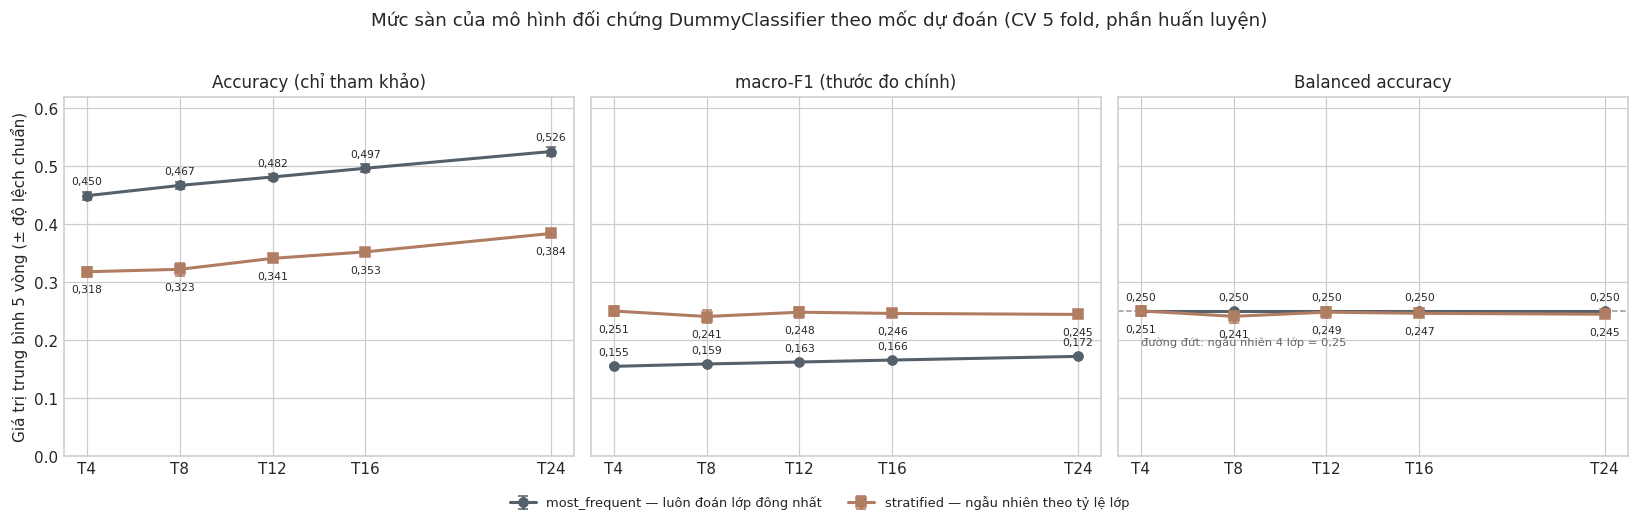

**Nhận xét:** `most_frequent` đạt accuracy từ 44,95% (tuần 4) đến 52,57% (tuần 24) nhưng macro-F1 chỉ 0,16–0,17, balanced accuracy đúng bằng 0,25 và recall của Withdrawn, Fail, Distinction bằng 0: mô hình không phát hiện được sinh viên có nguy cơ nào dù accuracy gần 50%. `stratified` có macro-F1 0,24–0,25 và balanced accuracy xấp xỉ 0,25 — mức đoán mò. Vì vậy **mức sàn** cho các mô hình học máy là macro-F1 khoảng 0,25 và balanced accuracy 0,25 ở mọi mốc; accuracy không phù hợp làm thước đo chính. Khung huấn luyện thử (đọc dữ liệu → pipeline → 5 fold → chỉ số theo vòng và ma trận nhầm lẫn) đã chạy ổn định ở cả 5 mốc.

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
style = {'most_frequent': dict(color='#55606a', marker='o'), 'stratified': dict(color='#b07d62', marker='s')}
titles = {'accuracy': 'Accuracy (chỉ tham khảo)', 'f1_macro': 'macro-F1 (thước đo chính)',
          'balanced_accuracy': 'Balanced accuracy'}
for ax, m_ in zip(axes, METRICS):
    for strat in DUMMY_STRATEGIES:
        sub = baseline_summary[baseline_summary['Chiến lược'] == strat]
        ax.errorbar(WEEKS, sub[f'{m_} (TB)'], yerr=sub[f'{m_} (ĐLC)'], capsize=3, linewidth=2,
                    label=f'{strat} — {DUMMY_STRATEGIES[strat].lower()}', **style[strat])
        for w, v in zip(WEEKS, sub[f'{m_} (TB)']):
            ax.annotate(f'{v:.3f}'.replace('.', ','), (w, v), textcoords='offset points',
                        xytext=(0, 7 if strat == 'most_frequent' else -14), ha='center', fontsize=7)
    if m_ == 'balanced_accuracy':
        ax.axhline(0.25, color='#999', linestyle='--', linewidth=1)
        ax.text(WEEKS[0], 0.19, 'đường đứt: ngẫu nhiên 4 lớp = 0,25', ha='left', fontsize=7.5, color='#666')
    ax.set_xticks(WEEKS, [f'T{w}' for w in WEEKS]); ax.set_title(titles[m_]); ax.set_ylim(0, 0.62)
axes[0].set_ylabel('Giá trị trung bình 5 vòng (± độ lệch chuẩn)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Mức sàn của mô hình đối chứng DummyClassifier theo mốc dự đoán (CV 5 fold, phần huấn luyện)', y=1.02)
fig.tight_layout()
save_figure(fig, '4_6_2_baseline_metrics'); plt.show()

mf = baseline_summary[baseline_summary['Chiến lược'] == 'most_frequent'].set_index('Mốc dự đoán (tuần)')
st = baseline_summary[baseline_summary['Chiến lược'] == 'stratified'].set_index('Mốc dự đoán (tuần)')
comment(f"`most_frequent` đạt accuracy từ {vn_pct(100 * mf['accuracy (TB)'].min())} (tuần 4) đến "
        f"{vn_pct(100 * mf['accuracy (TB)'].max())} (tuần 24) nhưng macro-F1 chỉ {vn2(mf['f1_macro (TB)'].min())}–"
        f"{vn2(mf['f1_macro (TB)'].max())}, balanced accuracy đúng bằng 0,25 và recall của Withdrawn, Fail, Distinction bằng 0: "
        "mô hình không phát hiện được sinh viên có nguy cơ nào dù accuracy gần 50%. `stratified` có macro-F1 "
        f"{vn2(st['f1_macro (TB)'].min())}–{vn2(st['f1_macro (TB)'].max())} và balanced accuracy xấp xỉ 0,25 — mức đoán mò. "
        f"Vì vậy **mức sàn** cho các mô hình học máy là macro-F1 khoảng {vn2(max(mf['f1_macro (TB)'].max(), st['f1_macro (TB)'].max()))} "
        "và balanced accuracy 0,25 ở mọi mốc; accuracy không phù hợp làm thước đo chính. Khung huấn luyện thử (đọc dữ liệu → "
        "pipeline → 5 fold → chỉ số theo vòng và ma trận nhầm lẫn) đã chạy ổn định ở cả 5 mốc.")

### 4.6.3. Sử dụng khung huấn luyện thử cho giai đoạn sau

Để huấn luyện một mô hình học máy đã đề xuất, chỉ cần thay `DummyClassifier` (và chọn phương án mất cân bằng):

```python
import modeling_pipeline as mp
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train_df = mp.load_modeling_data(8, 'train')
X, y = mp.make_xy(train_df)
model = mp.build_imbalance_pipeline('none', estimator=make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))
folds_df, cm = mp.evaluate_cv(model, X, y, mp.cv_splits(train_df))
```

Kết quả so sánh với bảng `4_6_2_baseline_summary.csv`. Tập `week{N}_test.csv` vẫn chưa được dùng.

### Kiểm tra cuối: dữ liệu và code của nhóm không bị thay đổi

In [37]:
protected_after = {p.relative_to(ROOT).as_posix(): sha256_file(p) for p in protected_paths}
integrity = pd.DataFrame({'Tệp': list(protected_before),
                          'Không thay đổi': [protected_before[k] == protected_after[k] for k in protected_before]})
display(integrity)
assert integrity['Không thay đổi'].all(), 'Một tệp của nhóm đã bị thay đổi!'
outputs = sorted([*TABLE_DIR.glob('4_*.csv'), *FIG_DIR.glob('4_*.png'), ASSIGN_PATH, MANIFEST_PATH, *mp.MODEL_DATA_DIR.glob('*'), ROOT / 'src' / 'modeling_pipeline.py',
                  PRE_DIR / 'selected_features.json'])
display(pd.DataFrame({'Tệp đầu ra': [p.relative_to(ROOT).as_posix() for p in outputs]}))

,Tệp,Không thay đổi
0,data/preprocessed/student_base.csv,True
1,data/preprocessed/oulad_week4.csv,True
2,data/preprocessed/oulad_week8.csv,True
3,data/preprocessed/oulad_week12.csv,True
4,data/preprocessed/oulad_week16.csv,True
5,data/preprocessed/oulad_week24.csv,True
6,data/preprocessed/feature_manifest.json,True
7,preprocess.ipynb,True
8,modeling.ipynb,True


,Tệp đầu ra
0,data/modeling/modeling_manifest.json
1,data/modeling/README.md
2,data/modeling/week12_test.csv
3,data/modeling/week12_train.csv
4,data/modeling/week16_test.csv
...,...
59,report/tables/4_6_1_algorithm_candidates.csv
60,report/tables/4_6_2_baseline_confusion.csv
61,report/tables/4_6_2_baseline_folds.csv
62,report/tables/4_6_2_baseline_summary.csv
